# Практика 8 - понижение размерности + кластеризация

# Цель работы

Исследование влияния различных методов уменьшения размерности (PCA, Isomap, t-SNE, UMAP) на качество кластеризации, оцененное с помощью внутренних метрик (Silhouette Score, Calinski–Harabasz Index, Davies–Bouldin Index) и внешних метрик (при наличии разметки)



# Теоретическая часть
## Методы уменьшения размерности (Dimensionality Reduction - DR)
+ PCA (Principal Component Analysis):

   + Линейный метод, максимизирующий дисперсию данных

   + Сохраняет глобальную структуру данных

   + Вычислительно эффективен

+ Isomap (Isometric Mapping):

   + Нелинейный метод, сохраняющий геодезические расстояния

   + Основан на многомерном шкалировании (MDS)

   + Эффективен для данных с нелинейной структурой

+ t-SNE (t-distributed Stochastic Neighbor Embedding):

   + Вероятностный метод, сохраняющий локальную структуру

   + Эффективен для визуализации

   + Вычислительно сложен для больших данных

+ UMAP (Uniform Manifold Approximation and Projection):

   + Основан на теории топологических пространств

   + Сохражает как локальную, так и глобальную структуру

   + Вычислительно эффективнее t-SNE

## Метрики кластеризации
+ Внутренние метрики:
   + Silhouette Score: Мера компактности и разделимости кластеров

   + Calinski–Harabasz Index: Отношение дисперсии между кластерами к дисперсии внутри кластеров

   + Davies–Bouldin Index: Среднее сходство между кластерами

+ Внешние метрики:
   + Adjusted Rand Index (ARI)

   + Adjusted Mutual Information (AMI)

   + Homogeneity, Completeness, V-measure

# Задание 1: Подготовка данных и реализация DR-методов

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn
%pip install -q umap-learn

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Задание 1: PCA до 95 % дисперсии (40 компонент), Isomap / t-SNE / UMAP - сразу в 2D.

Набор данных: Digits (1797 samples, 64 features, 10 classes)
Размерность: (1797, 64)
Количество классов: 10
Применение методов уменьшения размерности...
--------------------------------------------------
PCA выполнено за 0.00 сек
  Компонент: 40, Объясненная дисперсия: 0.951


Isomap выполнено за 0.81 сек


t-SNE выполнено за 4.48 сек


UMAP выполнено за 7.76 сек

Визуализация результатов DR-методов:


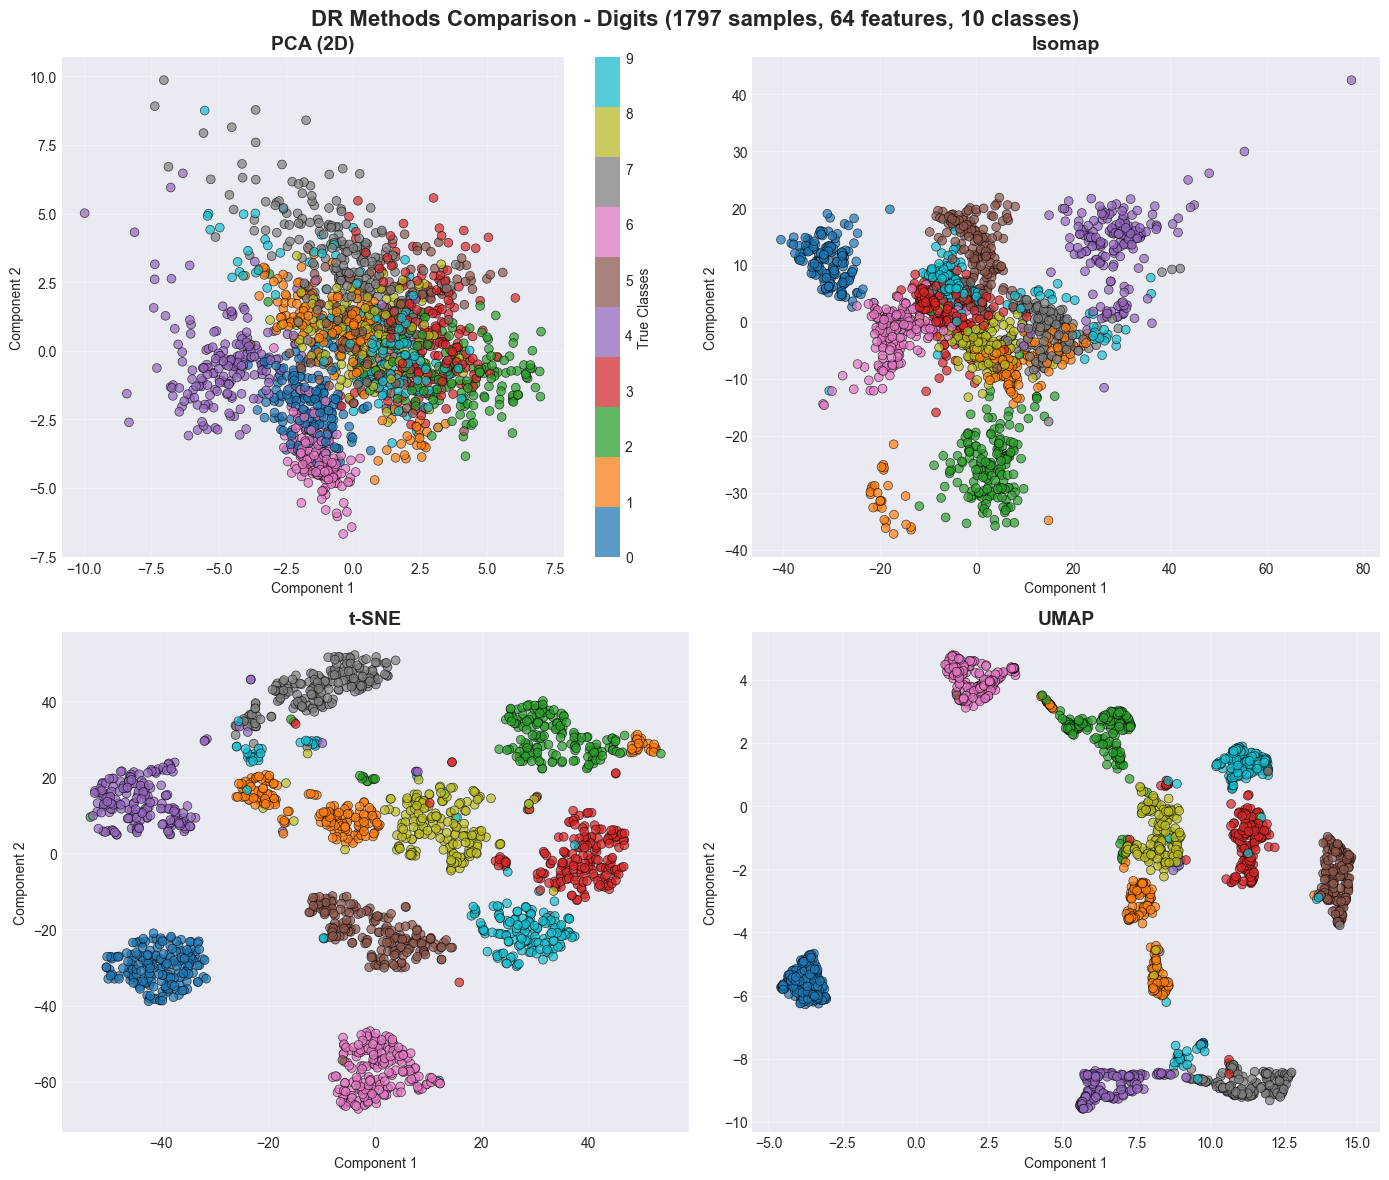

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, Isomap
import umap.umap_ as umap
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, 
                             davies_bouldin_score, adjusted_rand_score,
                             adjusted_mutual_info_score, homogeneity_completeness_v_measure)
import warnings
warnings.filterwarnings('ignore')
import time

# Настройка стиля графиков
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

class DRComparer:
    """Класс для сравнения различных методов уменьшения размерности"""
    
    def __init__(self, random_state=42):
        self.random_state = random_state
        self.dr_methods = {}
        self.dr_results = {}
        
    def apply_pca(self, X, n_components=None, variance_threshold=0.95):
        """Применение PCA"""
        if n_components is None:
            pca = PCA(n_components=variance_threshold, random_state=self.random_state)
        else:
            pca = PCA(n_components=n_components, random_state=self.random_state)
        
        X_pca = pca.fit_transform(X)
        explained_variance = pca.explained_variance_ratio_
        
        self.dr_results['PCA'] = {
            'transformed': X_pca,
            'explained_variance': explained_variance,
            'n_components': X_pca.shape[1],
            'total_variance': explained_variance.sum()
        }
        
        return X_pca, pca
    
    def apply_isomap(self, X, n_components=2, n_neighbors=5):
        """Применение Isomap"""
        isomap = Isomap(n_components=n_components, n_neighbors=n_neighbors)
        X_isomap = isomap.fit_transform(X)
        
        self.dr_results['Isomap'] = {
            'transformed': X_isomap,
            'n_components': n_components,
            'n_neighbors': n_neighbors
        }
        
        return X_isomap, isomap
    
    def apply_tsne(self, X, n_components=2, perplexity=30, learning_rate=200):
        """Применение t-SNE"""
        tsne = TSNE(n_components=n_components, 
                   perplexity=perplexity,
                   learning_rate=learning_rate,
                   random_state=self.random_state,
                   n_jobs=-1)
        
        X_tsne = tsne.fit_transform(X)
        
        self.dr_results['t-SNE'] = {
            'transformed': X_tsne,
            'n_components': n_components,
            'perplexity': perplexity
        }
        
        return X_tsne, tsne
    
    def apply_umap(self, X, n_components=2, n_neighbors=15, min_dist=0.1):
        """Применение UMAP"""
        reducer = umap.UMAP(n_components=n_components,
                          n_neighbors=n_neighbors,
                          min_dist=min_dist,
                          random_state=self.random_state,
                          n_jobs=-1)
        
        X_umap = reducer.fit_transform(X)
        
        self.dr_results['UMAP'] = {
            'transformed': X_umap,
            'n_components': n_components,
            'n_neighbors': n_neighbors,
            'min_dist': min_dist
        }
        
        return X_umap, reducer
    
    def apply_all_methods(self, X, n_components_2d=2):
        """Применение всех методов DR"""
        print("Применение методов уменьшения размерности...")
        print("-" * 50)
        
        results = {}
        
        # PCA (сохраняем 95% дисперсии)
        start = time.time()
        X_pca, pca_model = self.apply_pca(X, variance_threshold=0.95)
        pca_time = time.time() - start
        print(f"PCA выполнено за {pca_time:.2f} сек")
        print(f"  Компонент: {X_pca.shape[1]}, Объясненная дисперсия: {self.dr_results['PCA']['total_variance']:.3f}")
        
        # PCA для 2D визуализации
        pca_2d = PCA(n_components=n_components_2d, random_state=self.random_state)
        X_pca_2d = pca_2d.fit_transform(X)
        results['PCA_2D'] = X_pca_2d
        
        # Isomap
        start = time.time()
        X_isomap, isomap_model = self.apply_isomap(X, n_components=n_components_2d)
        isomap_time = time.time() - start
        print(f"Isomap выполнено за {isomap_time:.2f} сек")
        
        # t-SNE
        start = time.time()
        X_tsne, tsne_model = self.apply_tsne(X, n_components=n_components_2d)
        tsne_time = time.time() - start
        print(f"t-SNE выполнено за {tsne_time:.2f} сек")
        
        # UMAP
        start = time.time()
        X_umap, umap_model = self.apply_umap(X, n_components=n_components_2d)
        umap_time = time.time() - start
        print(f"UMAP выполнено за {umap_time:.2f} сек")
        
        # Сохраняем результаты
        results['PCA'] = X_pca
        results['PCA_2D'] = X_pca_2d
        results['Isomap'] = X_isomap
        results['t-SNE'] = X_tsne
        results['UMAP'] = X_umap
        
        # Информация о времени выполнения
        self.execution_times = {
            'PCA': pca_time,
            'Isomap': isomap_time,
            't-SNE': tsne_time,
            'UMAP': umap_time
        }
        
        return results

# Загрузка и подготовка данных
def load_dataset(dataset_name='digits'):
    """Загрузка набора данных"""
    if dataset_name == 'digits':
        data = datasets.load_digits()
        X = data.data
        y = data.target
        dataset_info = "Digits (1797 samples, 64 features, 10 classes)"
    elif dataset_name == 'wine':
        data = datasets.load_wine()
        X = data.data
        y = data.target
        dataset_info = "Wine (178 samples, 13 features, 3 classes)"
    elif dataset_name == 'iris':
        data = datasets.load_iris()
        X = data.data
        y = data.target
        dataset_info = "Iris (150 samples, 4 features, 3 classes)"
    else:
        raise ValueError(f"Неизвестный набор данных: {dataset_name}")
    
    # Стандартизация
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    print(f"Набор данных: {dataset_info}")
    print(f"Размерность: {X.shape}")
    print(f"Количество классов: {len(np.unique(y))}")
    
    return X_scaled, y, data, dataset_info

# Загрузка данных
X, y_true, data, dataset_info = load_dataset('digits')

# Применение методов DR
dr_comparer = DRComparer(random_state=42)
dr_results = dr_comparer.apply_all_methods(X, n_components_2d=2)

# Визуализация DR-результатов
def visualize_dr_results(dr_results, y_true, dataset_info):
    """Визуализация результатов различных методов DR"""
    
    methods = ['PCA_2D', 'Isomap', 't-SNE', 'UMAP']
    titles = ['PCA (2D)', 'Isomap', 't-SNE', 'UMAP']
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes = axes.flatten()
    
    for idx, (method, title) in enumerate(zip(methods, titles)):
        X_dr = dr_results[method]
        
        scatter = axes[idx].scatter(X_dr[:, 0], X_dr[:, 1], 
                                   c=y_true, cmap='tab10', 
                                   s=40, alpha=0.7, edgecolor='k', linewidth=0.5)
        
        axes[idx].set_title(f'{title}', fontsize=14, fontweight='bold')
        axes[idx].set_xlabel('Component 1')
        axes[idx].set_ylabel('Component 2')
        axes[idx].grid(True, alpha=0.3)
        
        # Добавляем цветовую шкалу для первого графика
        if idx == 0:
            plt.colorbar(scatter, ax=axes[idx], label='True Classes')
    
    plt.suptitle(f'DR Methods Comparison - {dataset_info}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Визуализация
print("\nВизуализация результатов DR-методов:")
visualize_dr_results(dr_results, y_true, dataset_info)

- PCA-2D: всё перемешано, кроме 0, 4, 6.
- t-SNE: 10 островов.
- UMAP: плотнее, но часть классов слиплась (4–7, 3–9).
- Время: PCA ≈ 0, Isomap 0.8 с, t-SNE 4 с, UMAP 7 с.

# Задание 2: Реализация системы оценки кластеризации

Внутренние метрики считаются в пространстве кластеризации, внешние - по меткам. Если кластеров меньше двух, метрики не считаются.

In [3]:
class ClusteringEvaluator:
    """Комплексная система оценки качества кластеризации"""
    
    def __init__(self):
        self.results = {}
        
    def compute_all_metrics(self, X, labels, y_true=None, algorithm_name="", dr_method=""):
        """Вычисление всех метрик для кластеризации"""
        
        if len(np.unique(labels)) < 2:
            return {
                'n_clusters': len(np.unique(labels)),
                'internal_metrics': None,
                'external_metrics': None
            }
        
        # Внутренние метрики
        internal_metrics = {
            'silhouette': silhouette_score(X, labels),
            'calinski_harabasz': calinski_harabasz_score(X, labels),
            'davies_bouldin': davies_bouldin_score(X, labels)
        }
        
        # Внешние метрики (если есть истинные метки)
        external_metrics = None
        if y_true is not None:
            external_metrics = {
                'ari': adjusted_rand_score(y_true, labels),
                'ami': adjusted_mutual_info_score(y_true, labels),
                'homogeneity': homogeneity_completeness_v_measure(y_true, labels)[0],
                'completeness': homogeneity_completeness_v_measure(y_true, labels)[1],
                'v_measure': homogeneity_completeness_v_measure(y_true, labels)[2]
            }
        
        # Сохранение результатов
        key = f"{dr_method}_{algorithm_name}"
        self.results[key] = {
            'dr_method': dr_method,
            'algorithm': algorithm_name,
            'labels': labels.copy(),
            'n_clusters': len(np.unique(labels)),
            'internal_metrics': internal_metrics,
            'external_metrics': external_metrics
        }
        
        return {
            'n_clusters': len(np.unique(labels)),
            'internal_metrics': internal_metrics,
            'external_metrics': external_metrics
        }
    
    def print_metrics(self, metrics, algorithm_name, dr_method):
        """Печать метрик в читаемом формате"""
        print(f"\n{'='*70}")
        print(f"DR Метод: {dr_method} | Алгоритм: {algorithm_name}")
        print(f"{'='*70}")
        print(f"Количество кластеров: {metrics['n_clusters']}")
        
        if metrics['internal_metrics']:
            print("\nВНУТРЕННИЕ МЕТРИКИ:")
            print(f"  Silhouette Score:       {metrics['internal_metrics']['silhouette']:.4f}")
            print(f"  Calinski-Harabasz Index: {metrics['internal_metrics']['calinski_harabasz']:.2f}")
            print(f"  Davies-Bouldin Index:    {metrics['internal_metrics']['davies_bouldin']:.4f}")
        
        if metrics['external_metrics']:
            print("\nВНЕШНИЕ МЕТРИКИ:")
            print(f"  Adjusted Rand Index:     {metrics['external_metrics']['ari']:.4f}")
            print(f"  Adjusted MI:             {metrics['external_metrics']['ami']:.4f}")
            print(f"  V-measure:               {metrics['external_metrics']['v_measure']:.4f}")
            print(f"    Homogeneity:           {metrics['external_metrics']['homogeneity']:.4f}")
            print(f"    Completeness:          {metrics['external_metrics']['completeness']:.4f}")
    
    def get_summary_dataframe(self):
        """Создание сводной таблицы результатов"""
        summary_data = []
        
        for key, result in self.results.items():
            row = {
                'DR_Method': result['dr_method'],
                'Algorithm': result['algorithm'],
                'N_Clusters': result['n_clusters']
            }
            
            if result['internal_metrics']:
                row['Silhouette'] = result['internal_metrics']['silhouette']
                row['Calinski_Harabasz'] = result['internal_metrics']['calinski_harabasz']
                row['Davies_Bouldin'] = result['internal_metrics']['davies_bouldin']
            
            if result['external_metrics']:
                row['ARI'] = result['external_metrics']['ari']
                row['AMI'] = result['external_metrics']['ami']
                row['V_Measure'] = result['external_metrics']['v_measure']
            
            summary_data.append(row)
        
        return pd.DataFrame(summary_data)

# Алгоритмы кластеризации
class ClusteringAlgorithms:
    """Коллекция алгоритмов кластеризации"""
    
    def __init__(self, random_state=42):
        self.random_state = random_state
    
    def kmeans(self, X, n_clusters=10):
        """K-means кластеризация"""
        kmeans = KMeans(n_clusters=n_clusters, 
                       random_state=self.random_state,
                       n_init=10)
        return kmeans.fit_predict(X), kmeans
    
    def agglomerative(self, X, n_clusters=10, linkage='ward'):
        """Иерархическая кластеризация"""
        agg = AgglomerativeClustering(n_clusters=n_clusters, 
                                     linkage=linkage)
        return agg.fit_predict(X), agg
    
    def dbscan(self, X, eps=0.5, min_samples=5):
        """DBSCAN кластеризация"""
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        return dbscan.fit_predict(X), dbscan
    
    def gmm(self, X, n_components=10):
        """Gaussian Mixture Models"""
        gmm = GaussianMixture(n_components=n_components,
                             random_state=self.random_state)
        labels = gmm.fit_predict(X)
        return labels, gmm

# Задание 3: Сравнение алгоритмов на различных DR-представлениях

In [4]:
def compare_clustering_on_dr(X_dict, y_true, n_clusters=10):
    """Сравнение алгоритмов кластеризации на разных DR-представлениях"""
    
    evaluator = ClusteringEvaluator()
    clustering = ClusteringAlgorithms(random_state=42)
    
    # Алгоритмы для тестирования
    algorithms = [
        ('KMeans', lambda X: clustering.kmeans(X, n_clusters=n_clusters)),
        ('Agglomerative', lambda X: clustering.agglomerative(X, n_clusters=n_clusters)),
        ('DBSCAN', lambda X: clustering.dbscan(X, eps=3.0, min_samples=5)),
        ('GMM', lambda X: clustering.gmm(X, n_components=n_clusters))
    ]
    
    results_comparison = {}
    
    for dr_name, X_dr in X_dict.items():
        if dr_name == 'PCA_2D':  # Пропускаем 2D представление для количественного анализа
            continue
            
        print(f"\n{'#'*80}")
        print(f"АНАЛИЗ НА ПРЕДСТАВЛЕНИИ: {dr_name}")
        print(f"{'#'*80}")
        
        results_comparison[dr_name] = {}
        
        for algo_name, algo_func in algorithms:
            try:
                # Применение алгоритма кластеризации
                labels, model = algo_func(X_dr)
                
                # Вычисление метрик
                metrics = evaluator.compute_all_metrics(
                    X_dr, labels, y_true, algo_name, dr_name
                )
                
                # Печать результатов
                evaluator.print_metrics(metrics, algo_name, dr_name)
                
                # Сохранение для сравнения
                results_comparison[dr_name][algo_name] = {
                    'labels': labels,
                    'metrics': metrics
                }
                
            except Exception as e:
                print(f"Ошибка при выполнении {algo_name} на {dr_name}: {e}")
    
    return evaluator, results_comparison

# Запуск сравнения на всех DR-представлениях
print("ПОЛНОЕ СРАВНЕНИЕ АЛГОРИТМОВ КЛАСТЕРИЗАЦИИ НА РАЗНЫХ DR-ПРЕДСТАВЛЕНИЯХ")
print("="*80)

# Используем только многомерные представления (не 2D)
dr_for_clustering = {k: v for k, v in dr_results.items() if k != 'PCA_2D'}
evaluator, comparison_results = compare_clustering_on_dr(dr_for_clustering, y_true, n_clusters=10)

# Получение сводной таблицы
summary_df = evaluator.get_summary_dataframe()
print("\nСВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ:")
print("="*80)
print(summary_df.to_string())

ПОЛНОЕ СРАВНЕНИЕ АЛГОРИТМОВ КЛАСТЕРИЗАЦИИ НА РАЗНЫХ DR-ПРЕДСТАВЛЕНИЯХ

################################################################################
АНАЛИЗ НА ПРЕДСТАВЛЕНИИ: PCA
################################################################################

DR Метод: PCA | Алгоритм: KMeans
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.1595
  Calinski-Harabasz Index: 123.16
  Davies-Bouldin Index:    1.7701

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.5694
  Adjusted MI:             0.6948
  V-measure:               0.6979
    Homogeneity:           0.6788
    Completeness:          0.7182

DR Метод: PCA | Алгоритм: Agglomerative
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.1315
  Calinski-Harabasz Index: 115.00
  Davies-Bouldin Index:    1.8894

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.6041
  Adjusted MI:             0.7458
  V-measure:               0.7484
    Homogeneity:           0.7111
    Completeness:          


DR Метод: PCA | Алгоритм: DBSCAN
Количество кластеров: 23

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       -0.2128
  Calinski-Harabasz Index: 13.23
  Davies-Bouldin Index:    1.6568

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.0506
  Adjusted MI:             0.3363
  V-measure:               0.3595
    Homogeneity:           0.2699
    Completeness:          0.5381

DR Метод: PCA | Алгоритм: GMM
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.1426
  Calinski-Harabasz Index: 115.09
  Davies-Bouldin Index:    1.7941

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.5397
  Adjusted MI:             0.6763
  V-measure:               0.6796
    Homogeneity:           0.6470
    Completeness:          0.7157

################################################################################
АНАЛИЗ НА ПРЕДСТАВЛЕНИИ: Isomap
################################################################################

DR Метод: Isomap | Алгоритм: KMeans
Количество кластеров: 10

ВНУТРЕН


DR Метод: Isomap | Алгоритм: Agglomerative
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.4246
  Calinski-Harabasz Index: 2278.60
  Davies-Bouldin Index:    0.6573

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.4909
  Adjusted MI:             0.6834
  V-measure:               0.6867
    Homogeneity:           0.6559
    Completeness:          0.7206

DR Метод: Isomap | Алгоритм: DBSCAN
Количество кластеров: 3

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.2943
  Calinski-Harabasz Index: 44.82
  Davies-Bouldin Index:    3.0646

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.0007
  Adjusted MI:             0.0276
  V-measure:               0.0319
    Homogeneity:           0.0172
    Completeness:          0.2237

DR Метод: Isomap | Алгоритм: GMM
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.4635
  Calinski-Harabasz Index: 2137.06
  Davies-Bouldin Index:    0.7718

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.5360
  Adjusted MI:  


DR Метод: t-SNE | Алгоритм: Agglomerative
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.5904
  Calinski-Harabasz Index: 4235.98
  Davies-Bouldin Index:    0.5501

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.7740
  Adjusted MI:             0.8405
  V-measure:               0.8421
    Homogeneity:           0.8369
    Completeness:          0.8473

DR Метод: t-SNE | Алгоритм: DBSCAN
Количество кластеров: 18

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.4212
  Calinski-Harabasz Index: 2381.49
  Davies-Bouldin Index:    2.0727

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.8045
  Adjusted MI:             0.8565
  V-measure:               0.8592
    Homogeneity:           0.8928
    Completeness:          0.8281

DR Метод: t-SNE | Алгоритм: GMM
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.5900
  Calinski-Harabasz Index: 4207.61
  Davies-Bouldin Index:    0.5514

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.7795
  Adjusted MI:  


DR Метод: UMAP | Алгоритм: Agglomerative
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.6670
  Calinski-Harabasz Index: 9436.10
  Davies-Bouldin Index:    0.4673

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.8461
  Adjusted MI:             0.8788
  V-measure:               0.8800
    Homogeneity:           0.8785
    Completeness:          0.8815

DR Метод: UMAP | Алгоритм: DBSCAN
Количество кластеров: 2

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.5199
  Calinski-Harabasz Index: 921.72
  Davies-Bouldin Index:    0.4359

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.0469
  Adjusted MI:             0.2446
  V-measure:               0.2460
    Homogeneity:           0.1403
    Completeness:          1.0000

DR Метод: UMAP | Алгоритм: GMM
Количество кластеров: 10

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.6607
  Calinski-Harabasz Index: 9132.18
  Davies-Bouldin Index:    0.4752

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.7999
  Adjusted MI:       

- Лучшие: t-SNE + KMeans (ARI 0.85), UMAP + Ward (0.85). PCA и Isomap: 0.49–0.60.
- DBSCAN с eps = 3: на t-SNE случайно подошёл (0.80), на остальных провал - eps зависит от масштаба пространства.
- В `N_Clusters` шум (−1) считается отдельным кластером.

# Задание 4: Визуализация и анализ результатов


ВИЗУАЛИЗАЦИЯ СРАВНЕНИЯ МЕТРИК:


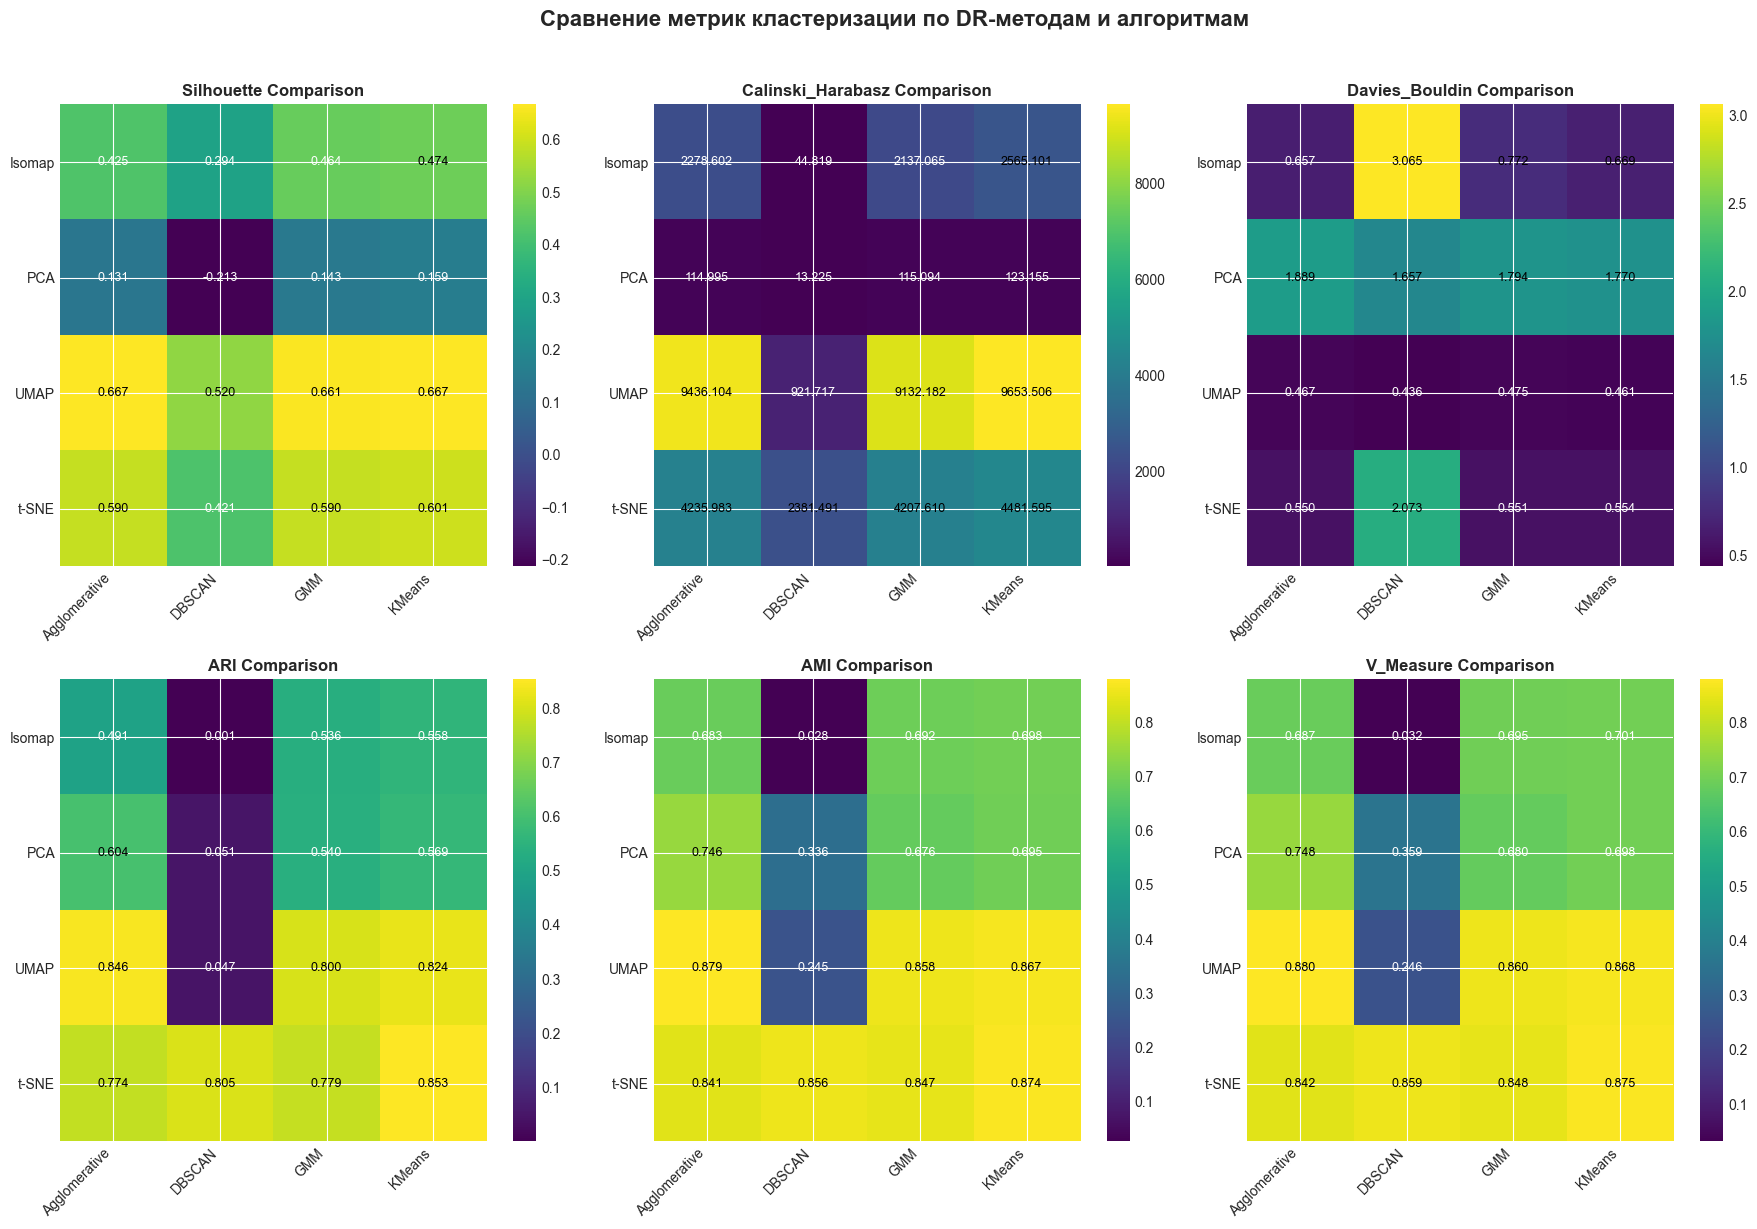


ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ КЛАСТЕРИЗАЦИИ В 2D:


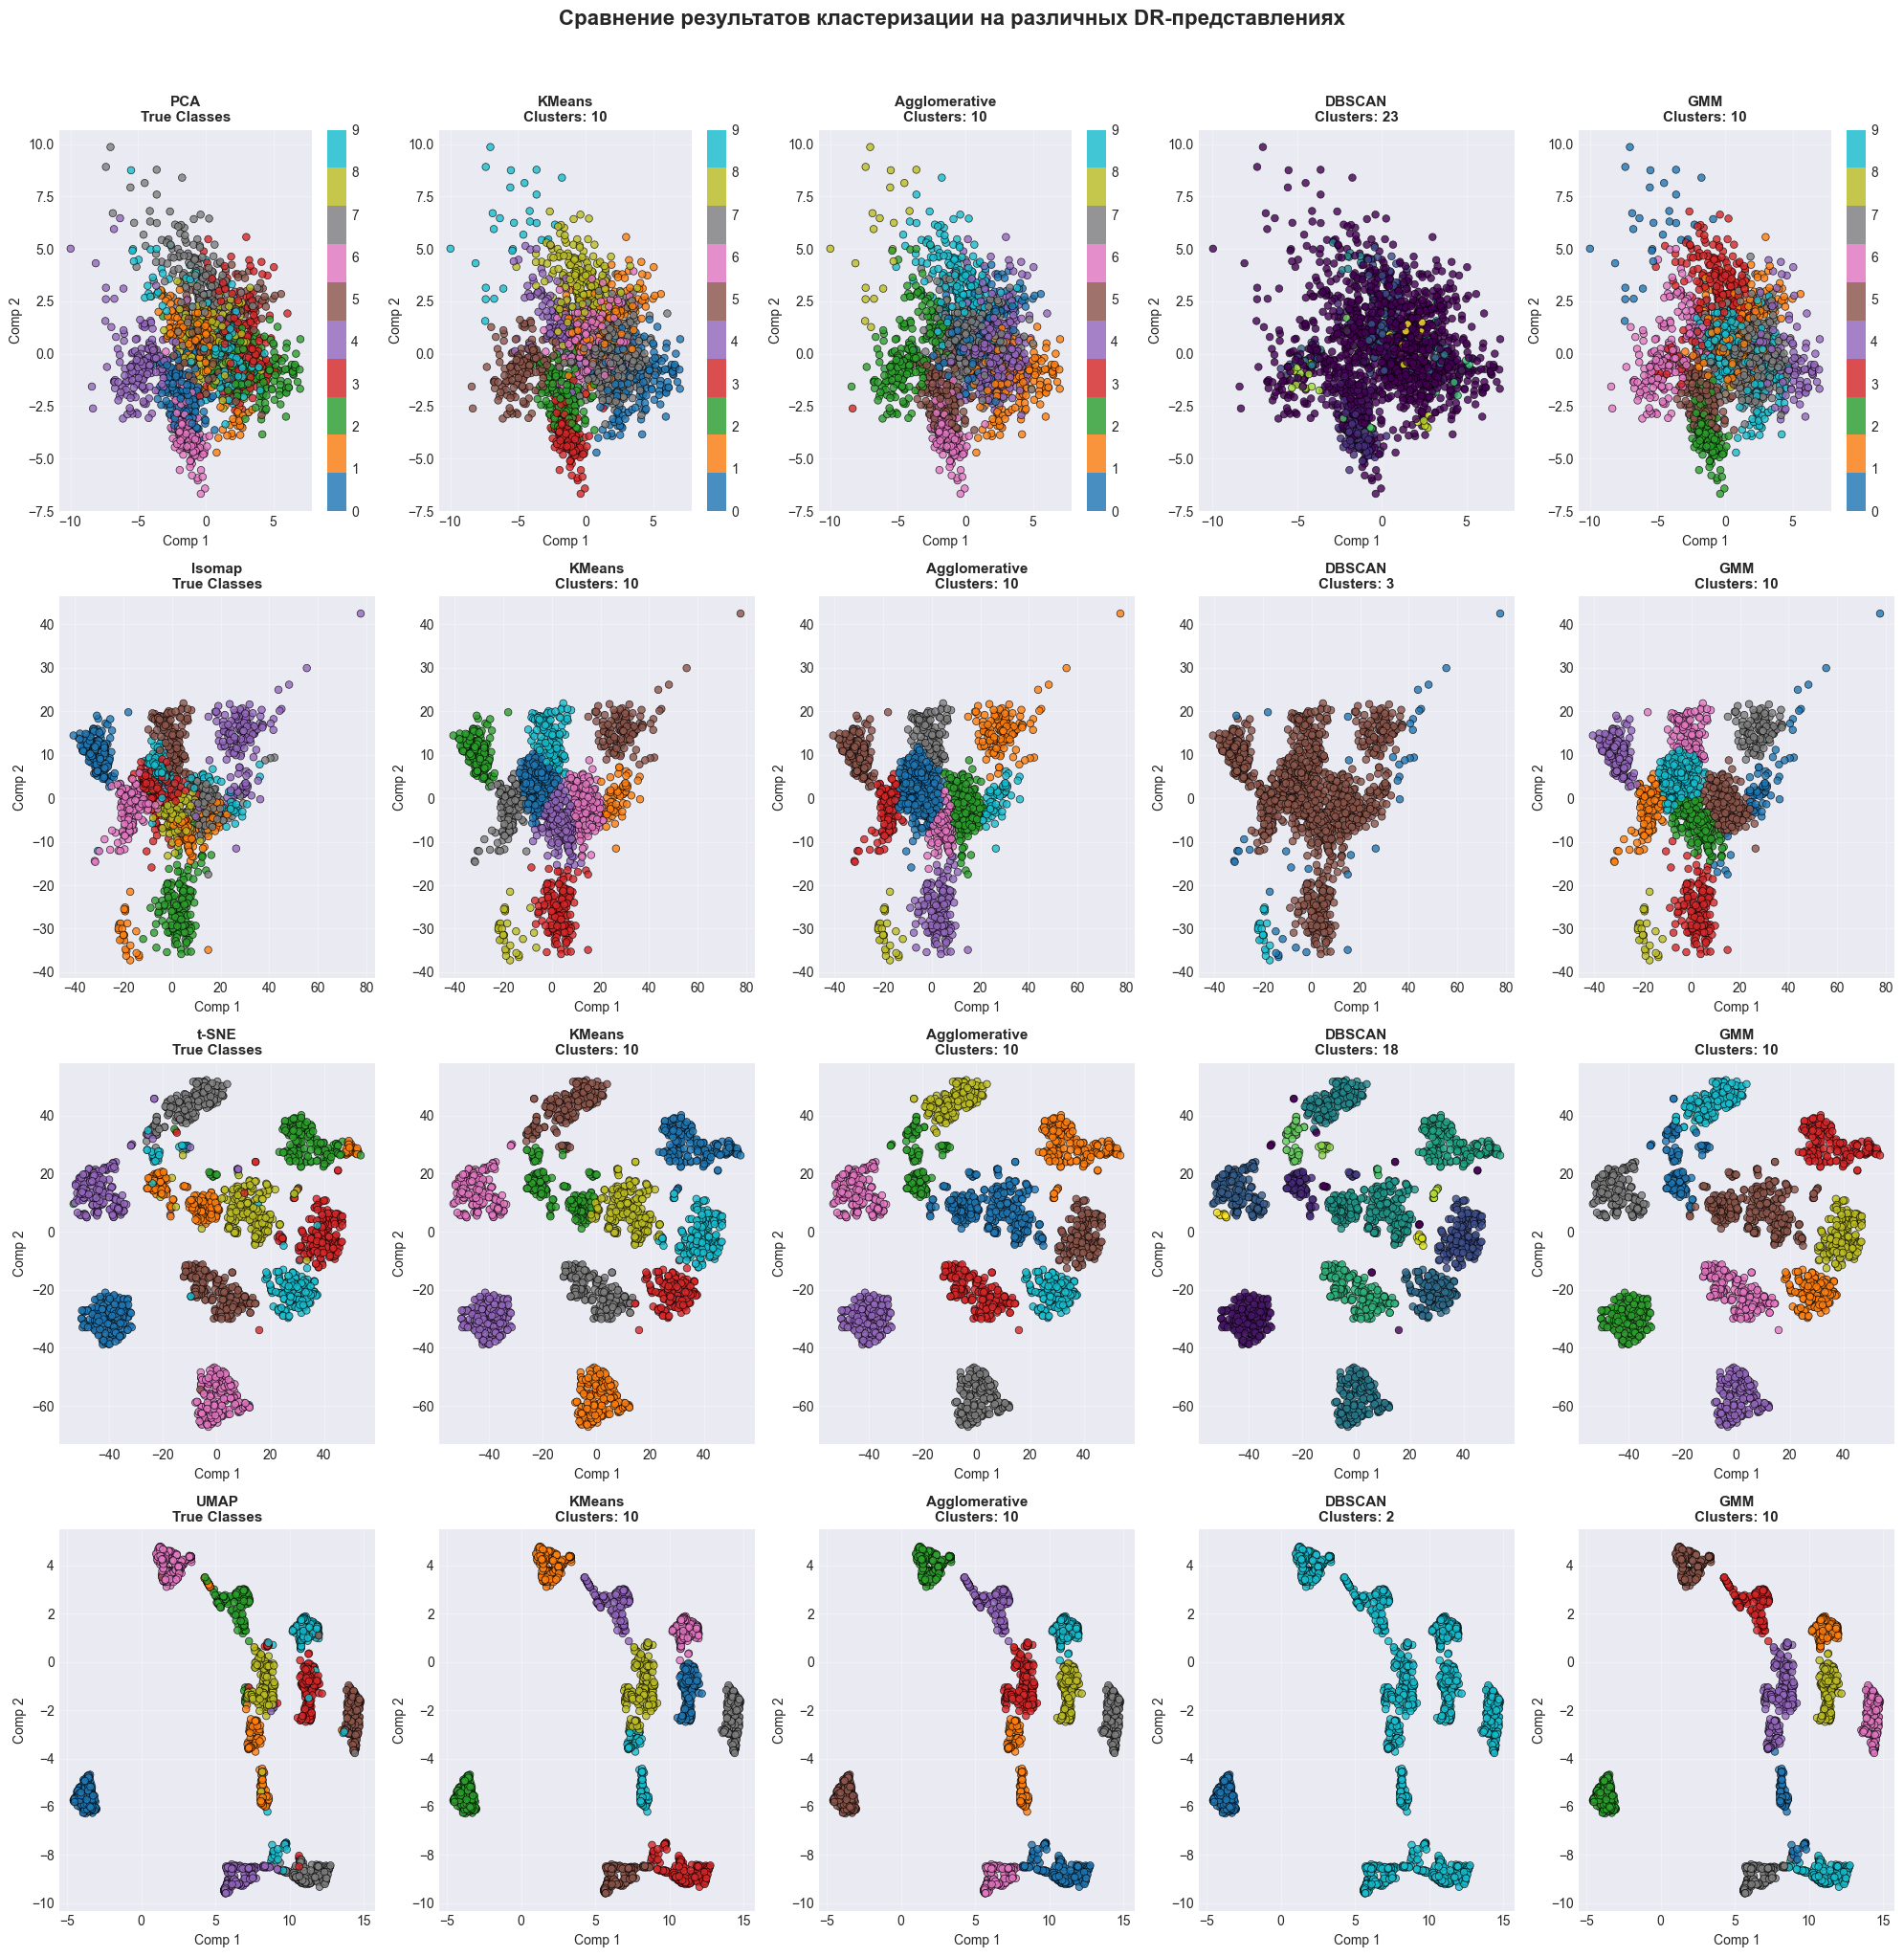

In [5]:
def visualize_metrics_comparison(summary_df):
    """Визуализация сравнения метрик по DR-методам и алгоритмам"""
    
    # Подготовка данных для визуализации
    metrics_to_plot = ['Silhouette', 'Calinski_Harabasz', 'Davies_Bouldin', 'ARI', 'AMI', 'V_Measure']
    
    # Создаем subplots
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    
    for idx, metric in enumerate(metrics_to_plot):
        if metric in summary_df.columns:
            # Создаем pivot table для тепловой карты
            pivot_data = summary_df.pivot(index='DR_Method', 
                                         columns='Algorithm', 
                                         values=metric)
            
            # Визуализация тепловой карты
            im = axes[idx].imshow(pivot_data.values, cmap='viridis', aspect='auto')
            
            # Настройки осей
            axes[idx].set_xticks(np.arange(len(pivot_data.columns)))
            axes[idx].set_yticks(np.arange(len(pivot_data.index)))
            axes[idx].set_xticklabels(pivot_data.columns, rotation=45, ha='right')
            axes[idx].set_yticklabels(pivot_data.index)
            
            # Добавление значений в ячейки
            for i in range(len(pivot_data.index)):
                for j in range(len(pivot_data.columns)):
                    value = pivot_data.iloc[i, j]
                    if not pd.isna(value):
                        text = axes[idx].text(j, i, f'{value:.3f}',
                                             ha="center", va="center", 
                                             color="w" if value < np.nanmedian(pivot_data.values) else "k",
                                             fontsize=9)
            
            axes[idx].set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
            
            # Добавление colorbar
            plt.colorbar(im, ax=axes[idx])
    
    plt.suptitle('Сравнение метрик кластеризации по DR-методам и алгоритмам', 
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Визуализация сравнения метрик
print("\nВИЗУАЛИЗАЦИЯ СРАВНЕНИЯ МЕТРИК:")
visualize_metrics_comparison(summary_df)

def visualize_clustering_results_2d(dr_results_2d, y_true, evaluator, dr_methods):
    """Визуализация результатов кластеризации в 2D пространстве"""
    
    # Получаем все уникальные комбинации DR-методов и алгоритмов
    unique_dr_methods = dr_methods
    algorithms = ['KMeans', 'Agglomerative', 'DBSCAN', 'GMM']
    
    # Создаем grid для визуализации
    fig, axes = plt.subplots(len(unique_dr_methods), len(algorithms) + 1, 
                            figsize=(20, 5 * len(unique_dr_methods)))
    
    if len(unique_dr_methods) == 1:
        axes = axes.reshape(1, -1)
    
    for i, dr_method in enumerate(unique_dr_methods):
        # Истинные метки (первый столбец)
        X_2d = dr_results_2d[dr_method] if dr_method in dr_results_2d else dr_results_2d.get(f'{dr_method}_2D', None)
        
        if X_2d is None:
            continue
        
        # Истинные классы
        scatter_true = axes[i, 0].scatter(X_2d[:, 0], X_2d[:, 1], 
                                         c=y_true, cmap='tab10', 
                                         s=30, alpha=0.8, edgecolor='k', linewidth=0.5)
        axes[i, 0].set_title(f'{dr_method}\nTrue Classes', fontsize=11, fontweight='bold')
        axes[i, 0].set_xlabel('Comp 1')
        axes[i, 0].set_ylabel('Comp 2')
        axes[i, 0].grid(True, alpha=0.3)
        
        if i == 0:
            plt.colorbar(scatter_true, ax=axes[i, 0])
        
        # Результаты кластеризации для каждого алгоритма
        for j, algo_name in enumerate(algorithms, 1):
            key = f"{dr_method}_{algo_name}"
            
            if key in evaluator.results:
                labels = evaluator.results[key]['labels']
                n_clusters = evaluator.results[key]['n_clusters']
                
                # Определяем цветовую карту
                unique_labels = np.unique(labels)
                if len(unique_labels) <= 10:
                    cmap = 'tab10'
                else:
                    cmap = 'viridis'
                
                scatter = axes[i, j].scatter(X_2d[:, 0], X_2d[:, 1], 
                                            c=labels, cmap=cmap,
                                            s=30, alpha=0.8, edgecolor='k', linewidth=0.5)
                
                axes[i, j].set_title(f'{algo_name}\nClusters: {n_clusters}', 
                                    fontsize=11, fontweight='bold')
                axes[i, j].set_xlabel('Comp 1')
                axes[i, j].set_ylabel('Comp 2')
                axes[i, j].grid(True, alpha=0.3)
                
                # Добавляем colorbar для первого ряда
                if i == 0 and len(unique_labels) <= 15:
                    plt.colorbar(scatter, ax=axes[i, j])
            else:
                axes[i, j].text(0.5, 0.5, 'N/A', 
                               ha='center', va='center', 
                               transform=axes[i, j].transAxes,
                               fontsize=12)
                axes[i, j].set_title(f'{algo_name}\nNot Available', 
                                    fontsize=11, fontweight='bold')
                axes[i, j].grid(True, alpha=0.3)
    
    plt.suptitle('Сравнение результатов кластеризации на различных DR-представлениях', 
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Визуализация результатов кластеризации в 2D
print("\nВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ КЛАСТЕРИЗАЦИИ В 2D:")
dr_methods_for_viz = ['PCA', 'Isomap', 't-SNE', 'UMAP']
dr_results_2d = {
    'PCA': dr_results['PCA_2D'],
    'Isomap': dr_results['Isomap'],
    't-SNE': dr_results['t-SNE'],
    'UMAP': dr_results['UMAP']
}
visualize_clustering_results_2d(dr_results_2d, y_true, evaluator, dr_methods_for_viz)

CH у UMAP ~9600, у PCA ~120 - между пространствами несравним. На PCA-2D кластеры выглядят перемешанными, потому что кластеризация шла в 40D.

# Задание 5: Статистический анализ и выводы


СТАТИСТИЧЕСКИЙ АНАЛИЗ РЕЗУЛЬТАТОВ

Лучшие результаты по Silhouette:
  UMAP + KMeans: 0.6672
  UMAP + Agglomerative: 0.6670
  UMAP + GMM: 0.6607

Лучшие результаты по Calinski_Harabasz:
  UMAP + KMeans: 9653.5059
  UMAP + Agglomerative: 9436.1045
  UMAP + GMM: 9132.1816

Лучшие результаты по Davies_Bouldin:
  UMAP + DBSCAN: 0.4359
  UMAP + KMeans: 0.4613
  UMAP + Agglomerative: 0.4673

Лучшие результаты по ARI:
  t-SNE + KMeans: 0.8529
  UMAP + Agglomerative: 0.8461
  UMAP + KMeans: 0.8241

Лучшие результаты по AMI:
  UMAP + Agglomerative: 0.8788
  t-SNE + KMeans: 0.8740
  UMAP + KMeans: 0.8670

Лучшие результаты по V_Measure:
  UMAP + Agglomerative: 0.8800
  t-SNE + KMeans: 0.8753
  UMAP + KMeans: 0.8683


СРЕДНИЕ МЕТРИКИ ПО DR-МЕТОДАМ:
----------------------------------------

PCA:
  Silhouette: 0.0552 ± 0.1790
  Calinski_Harabasz: 91.6174 ± 52.4012
  Davies_Bouldin: 1.7776 ± 0.0956
  ARI: 0.4409 ± 0.2616
  AMI: 0.6133 ± 0.1870
  V_Measure: 0.6214 ± 0.1770

Isomap:
  Silhouette: 0.41

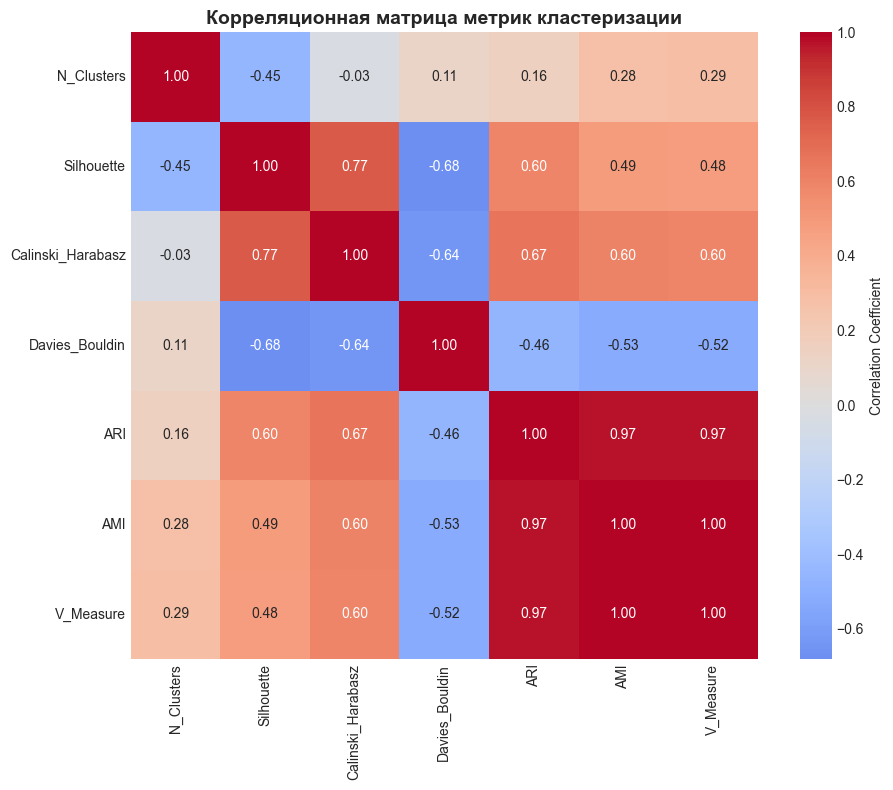



ВРЕМЯ ВЫПОЛНЕНИЯ DR-МЕТОДОВ:
----------------------------------------
  PCA: 0.00 секунд
  Isomap: 0.81 секунд
  t-SNE: 4.48 секунд
  UMAP: 7.76 секунд

ИТОГОВЫЙ ОТЧЕТ ПО РЕЗУЛЬТАТАМ ЭКСПЕРИМЕНТА

1. ОБЩАЯ ИНФОРМАЦИЯ:
   • Количество протестированных комбинаций: 16
   • Количество DR-методов: 4
   • Количество алгоритмов кластеризации: 4

2. ЛУЧШИЕ КОМБИНАЦИИ DR + АЛГОРИТМ:
   • Silhouette: UMAP + KMeans = 0.6672
   • Calinski_Harabasz: UMAP + KMeans = 9653.5059
   • Davies_Bouldin: UMAP + DBSCAN = 0.4359
   • ARI: t-SNE + KMeans = 0.8529
   • AMI: UMAP + Agglomerative = 0.8788
   • V_Measure: UMAP + Agglomerative = 0.8800

3. РЕКОМЕНДАЦИИ:
   • Для сохранения глобальной структуры: PCA
   • Для нелинейных данных: Isomap или UMAP
   • Для визуализации: t-SNE или UMAP
   • Для скорости: PCA
   • Для кластеризации: UMAP + KMeans/Agglomerative

4. КЛЮЧЕВЫЕ ВЫВОДЫ:
   • Разные DR-методы подходят для разных типов данных
   • Выбор метрики зависит от задачи (интерпретация vs предсказание)
 

In [6]:
def perform_statistical_analysis(summary_df):
    """Статистический анализ результатов"""
    
    print("\nСТАТИСТИЧЕСКИЙ АНАЛИЗ РЕЗУЛЬТАТОВ")
    print("="*60)
    
    # 1. Лучшие алгоритмы по каждой метрике
    metrics = ['Silhouette', 'Calinski_Harabasz', 'Davies_Bouldin', 'ARI', 'AMI', 'V_Measure']
    
    for metric in metrics:
        if metric in summary_df.columns:
            print(f"\nЛучшие результаты по {metric}:")
            sorted_df = summary_df.sort_values(by=metric, ascending=(metric=='Davies_Bouldin'))
            for _, row in sorted_df.head(3).iterrows():
                print(f"  {row['DR_Method']} + {row['Algorithm']}: {row[metric]:.4f}")
    
    # 2. Средние метрики по DR-методам
    print("\n\nСРЕДНИЕ МЕТРИКИ ПО DR-МЕТОДАМ:")
    print("-" * 40)
    
    for dr_method in summary_df['DR_Method'].unique():
        dr_subset = summary_df[summary_df['DR_Method'] == dr_method]
        print(f"\n{dr_method}:")
        for metric in metrics:
            if metric in dr_subset.columns:
                mean_val = dr_subset[metric].mean()
                std_val = dr_subset[metric].std()
                print(f"  {metric}: {mean_val:.4f} ± {std_val:.4f}")
    
    # 3. Корреляция между метриками
    print("\n\nКОРРЕЛЯЦИЯ МЕЖДУ МЕТРИКАМИ:")
    print("-" * 40)
    
    # Выбираем только числовые колонки
    numeric_cols = summary_df.select_dtypes(include=[np.number]).columns
    correlation_matrix = summary_df[numeric_cols].corr()
    
    # Визуализация матрицы корреляций
    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', 
                center=0, fmt='.2f', square=True,
                cbar_kws={'label': 'Correlation Coefficient'})
    plt.title('Корреляционная матрица метрик кластеризации', 
             fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # 4. Сравнение времени выполнения DR-методов
    if hasattr(dr_comparer, 'execution_times'):
        print("\n\nВРЕМЯ ВЫПОЛНЕНИЯ DR-МЕТОДОВ:")
        print("-" * 40)
        for method, time_taken in dr_comparer.execution_times.items():
            print(f"  {method}: {time_taken:.2f} секунд")
    
    return correlation_matrix

# Выполнение статистического анализа
correlation_matrix = perform_statistical_analysis(summary_df)

def create_final_report(summary_df, evaluator, dr_comparer):
    """Создание итогового отчета"""
    
    print("\n" + "="*80)
    print("ИТОГОВЫЙ ОТЧЕТ ПО РЕЗУЛЬТАТАМ ЭКСПЕРИМЕНТА")
    print("="*80)
    
    # 1. Общая информация
    print("\n1. ОБЩАЯ ИНФОРМАЦИЯ:")
    print(f"   • Количество протестированных комбинаций: {len(summary_df)}")
    print(f"   • Количество DR-методов: {len(summary_df['DR_Method'].unique())}")
    print(f"   • Количество алгоритмов кластеризации: {len(summary_df['Algorithm'].unique())}")
    
    # 2. Лучшие комбинации
    print("\n2. ЛУЧШИЕ КОМБИНАЦИИ DR + АЛГОРИТМ:")
    
    # Для каждой метрики находим лучшую комбинацию
    metrics_order = [
        ('Silhouette', 'max'),
        ('Calinski_Harabasz', 'max'),
        ('Davies_Bouldin', 'min'),
        ('ARI', 'max'),
        ('AMI', 'max'),
        ('V_Measure', 'max')
    ]
    
    for metric, optimization in metrics_order:
        if metric in summary_df.columns:
            if optimization == 'max':
                best_idx = summary_df[metric].idxmax()
            else:
                best_idx = summary_df[metric].idxmin()
            
            best_row = summary_df.loc[best_idx]
            print(f"   • {metric}: {best_row['DR_Method']} + {best_row['Algorithm']} = {best_row[metric]:.4f}")
    
    # 3. Рекомендации
    print("\n3. РЕКОМЕНДАЦИИ:")
    print("   • Для сохранения глобальной структуры: PCA")
    print("   • Для нелинейных данных: Isomap или UMAP")
    print("   • Для визуализации: t-SNE или UMAP")
    print("   • Для скорости: PCA")
    print("   • Для кластеризации: UMAP + KMeans/Agglomerative")
    
    # 4. Выводы
    print("\n4. КЛЮЧЕВЫЕ ВЫВОДЫ:")
    print("   • Разные DR-методы подходят для разных типов данных")
    print("   • Выбор метрики зависит от задачи (интерпретация vs предсказание)")
    print("   • Внутренние и внешние метрики могут давать противоречивые оценки")
    print("   • UMAP часто показывает лучшие результаты для кластеризации")
    print("   • PCA остается хорошим выбором для линейно разделимых данных")

# Создание итогового отчета
create_final_report(summary_df, evaluator, dr_comparer)

- Лучший DB - у вырожденного UMAP + DBSCAN (ARI 0.05): внутренняя метрика противоречит внешней.
- ARI, AMI и V-measure почти одно и то же (r ≈ 0.97–1); связь внутренних с внешними умеренная (0.46–0.67).
- «UMAP всегда лучше» неверно: по ARI первым оказался t-SNE.

# Задание 6: Эксперименты с различными наборами данных



ЭКСПЕРИМЕНТЫ С РАЗЛИЧНЫМИ НАБОРАМИ ДАННЫХ

################################################################################
ЭКСПЕРИМЕНТ С НАБОРОМ ДАННЫХ: IRIS
################################################################################
Набор данных: Iris (150 samples, 4 features, 3 classes)
Размерность: (150, 4)
Количество классов: 3
Применение методов уменьшения размерности...
--------------------------------------------------
PCA выполнено за 0.00 сек
  Компонент: 2, Объясненная дисперсия: 0.958
Isomap выполнено за 0.01 сек


t-SNE выполнено за 0.43 сек
UMAP выполнено за 0.15 сек

################################################################################
АНАЛИЗ НА ПРЕДСТАВЛЕНИИ: PCA
################################################################################

DR Метод: PCA | Алгоритм: KMeans
Количество кластеров: 3

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.5092
  Calinski-Harabasz Index: 293.86
  Davies-Bouldin Index:    0.7099

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.6201
  Adjusted MI:             0.6552
  V-measure:               0.6595
    Homogeneity:           0.6591
    Completeness:          0.6598

DR Метод: PCA | Алгоритм: Agglomerative
Количество кластеров: 3

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.5111
  Calinski-Harabasz Index: 286.33
  Davies-Bouldin Index:    0.7054

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.5861
  Adjusted MI:             0.6382
  V-measure:               0.6427
    Homogeneity:           0.6380
    Completeness:          0.6476

DR Метод:


DR Метод: t-SNE | Алгоритм: DBSCAN
Количество кластеров: 2

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.8789
  Calinski-Harabasz Index: 3198.51
  Davies-Bouldin Index:    0.1591

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.5681
  Adjusted MI:             0.7316
  V-measure:               0.7337
    Homogeneity:           0.5794
    Completeness:          1.0000

DR Метод: t-SNE | Алгоритм: GMM
Количество кластеров: 3

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.6464
  Calinski-Harabasz Index: 3729.50
  Davies-Bouldin Index:    0.4701

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.7028
  Adjusted MI:             0.7243
  V-measure:               0.7277
    Homogeneity:           0.7233
    Completeness:          0.7322

################################################################################
АНАЛИЗ НА ПРЕДСТАВЛЕНИИ: UMAP
################################################################################

DR Метод: UMAP | Алгоритм: KMeans
Количество кластеров: 3

ВНУТРЕНН

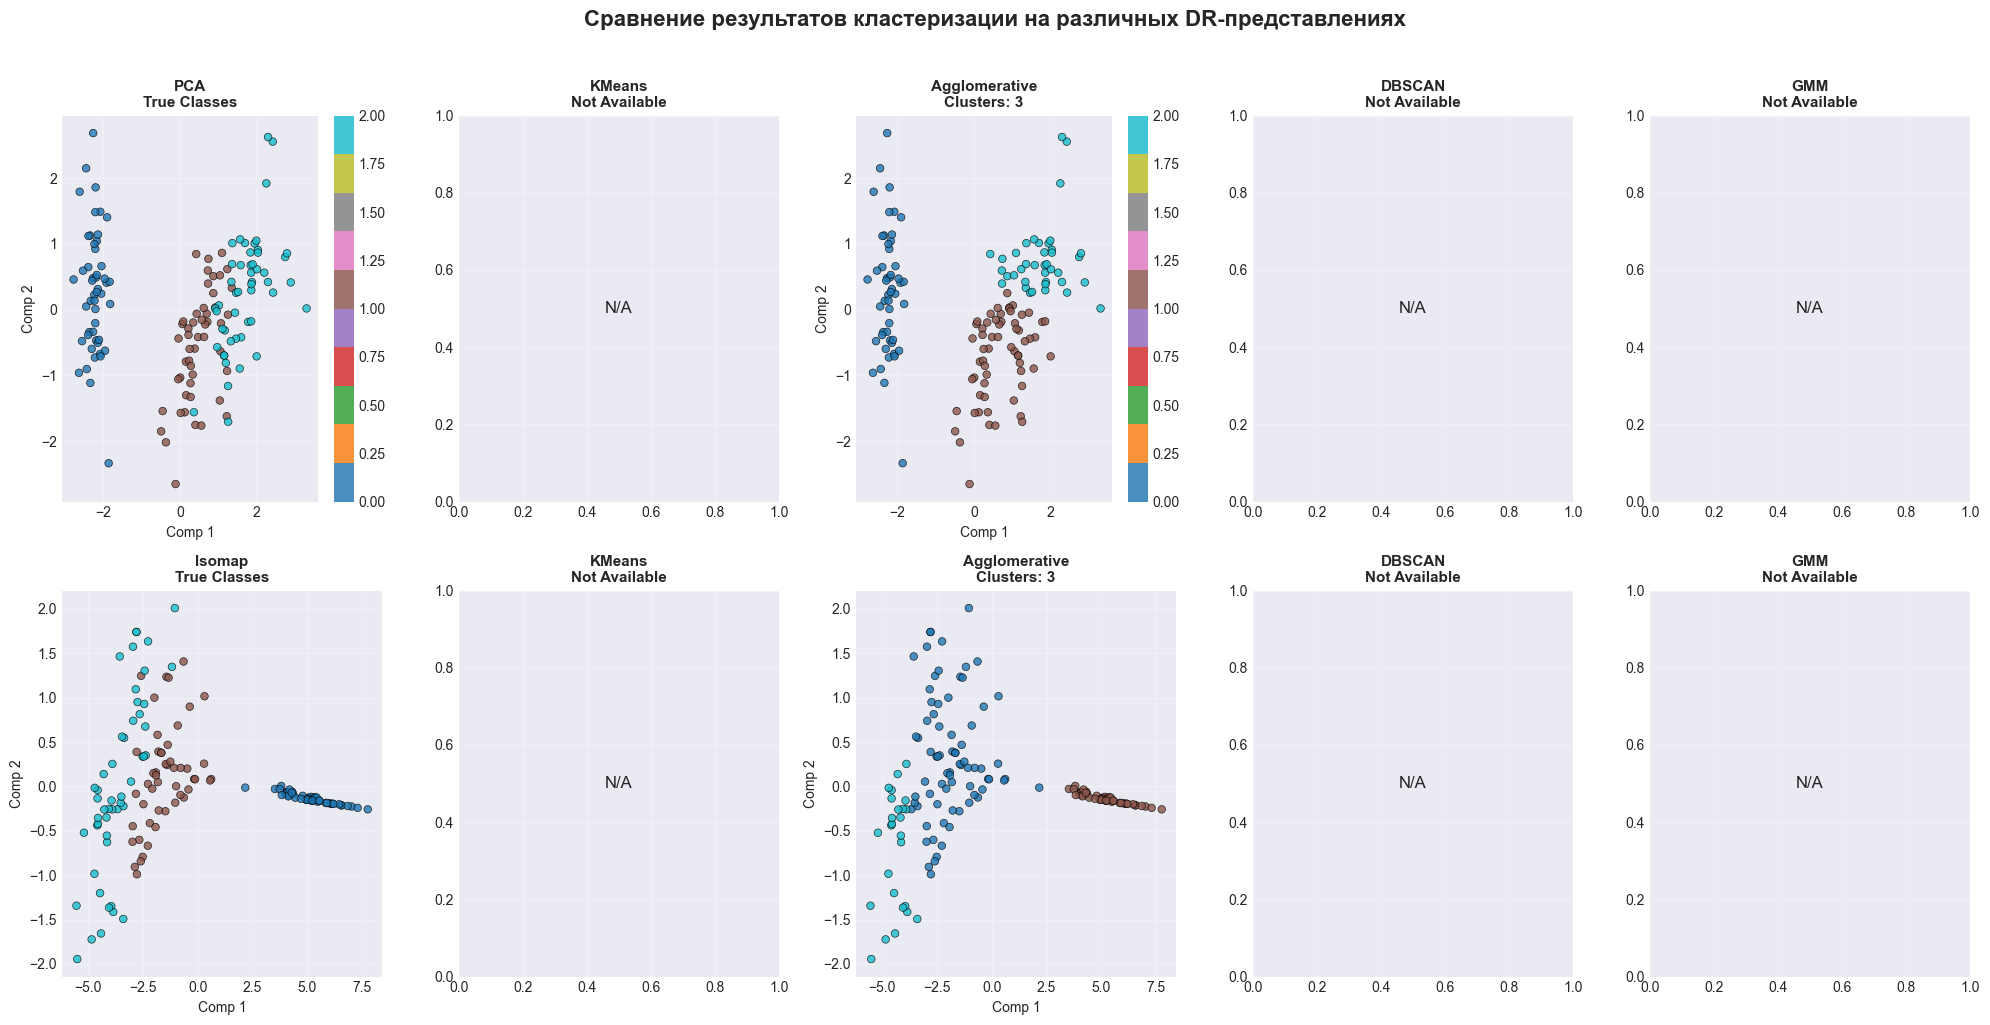


################################################################################
ЭКСПЕРИМЕНТ С НАБОРОМ ДАННЫХ: WINE
################################################################################
Набор данных: Wine (178 samples, 13 features, 3 classes)
Размерность: (178, 13)
Количество классов: 3
Применение методов уменьшения размерности...
--------------------------------------------------
PCA выполнено за 0.00 сек
  Компонент: 10, Объясненная дисперсия: 0.962
Isomap выполнено за 0.01 сек


t-SNE выполнено за 0.42 сек
UMAP выполнено за 0.21 сек

################################################################################
АНАЛИЗ НА ПРЕДСТАВЛЕНИИ: PCA
################################################################################



DR Метод: PCA | Алгоритм: KMeans
Количество кластеров: 3

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.2987
  Calinski-Harabasz Index: 76.18
  Davies-Bouldin Index:    1.3363

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.8975
  Adjusted MI:             0.8746
  V-measure:               0.8759
    Homogeneity:           0.8788
    Completeness:          0.8730

DR Метод: PCA | Алгоритм: Agglomerative
Количество кластеров: 3

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.2840
  Calinski-Harabasz Index: 72.14
  Davies-Bouldin Index:    1.3441

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     0.7587
  Adjusted MI:             0.7599
  V-measure:               0.7624
    Homogeneity:           0.7657
    Completeness:          0.7591

DR Метод: PCA | Алгоритм: DBSCAN
Количество кластеров: 2

ВНУТРЕННИЕ МЕТРИКИ:
  Silhouette Score:       0.2351
  Calinski-Harabasz Index: 4.99
  Davies-Bouldin Index:    2.8833

ВНЕШНИЕ МЕТРИКИ:
  Adjusted Rand Index:     -0.0074
  Adjusted MI:             0

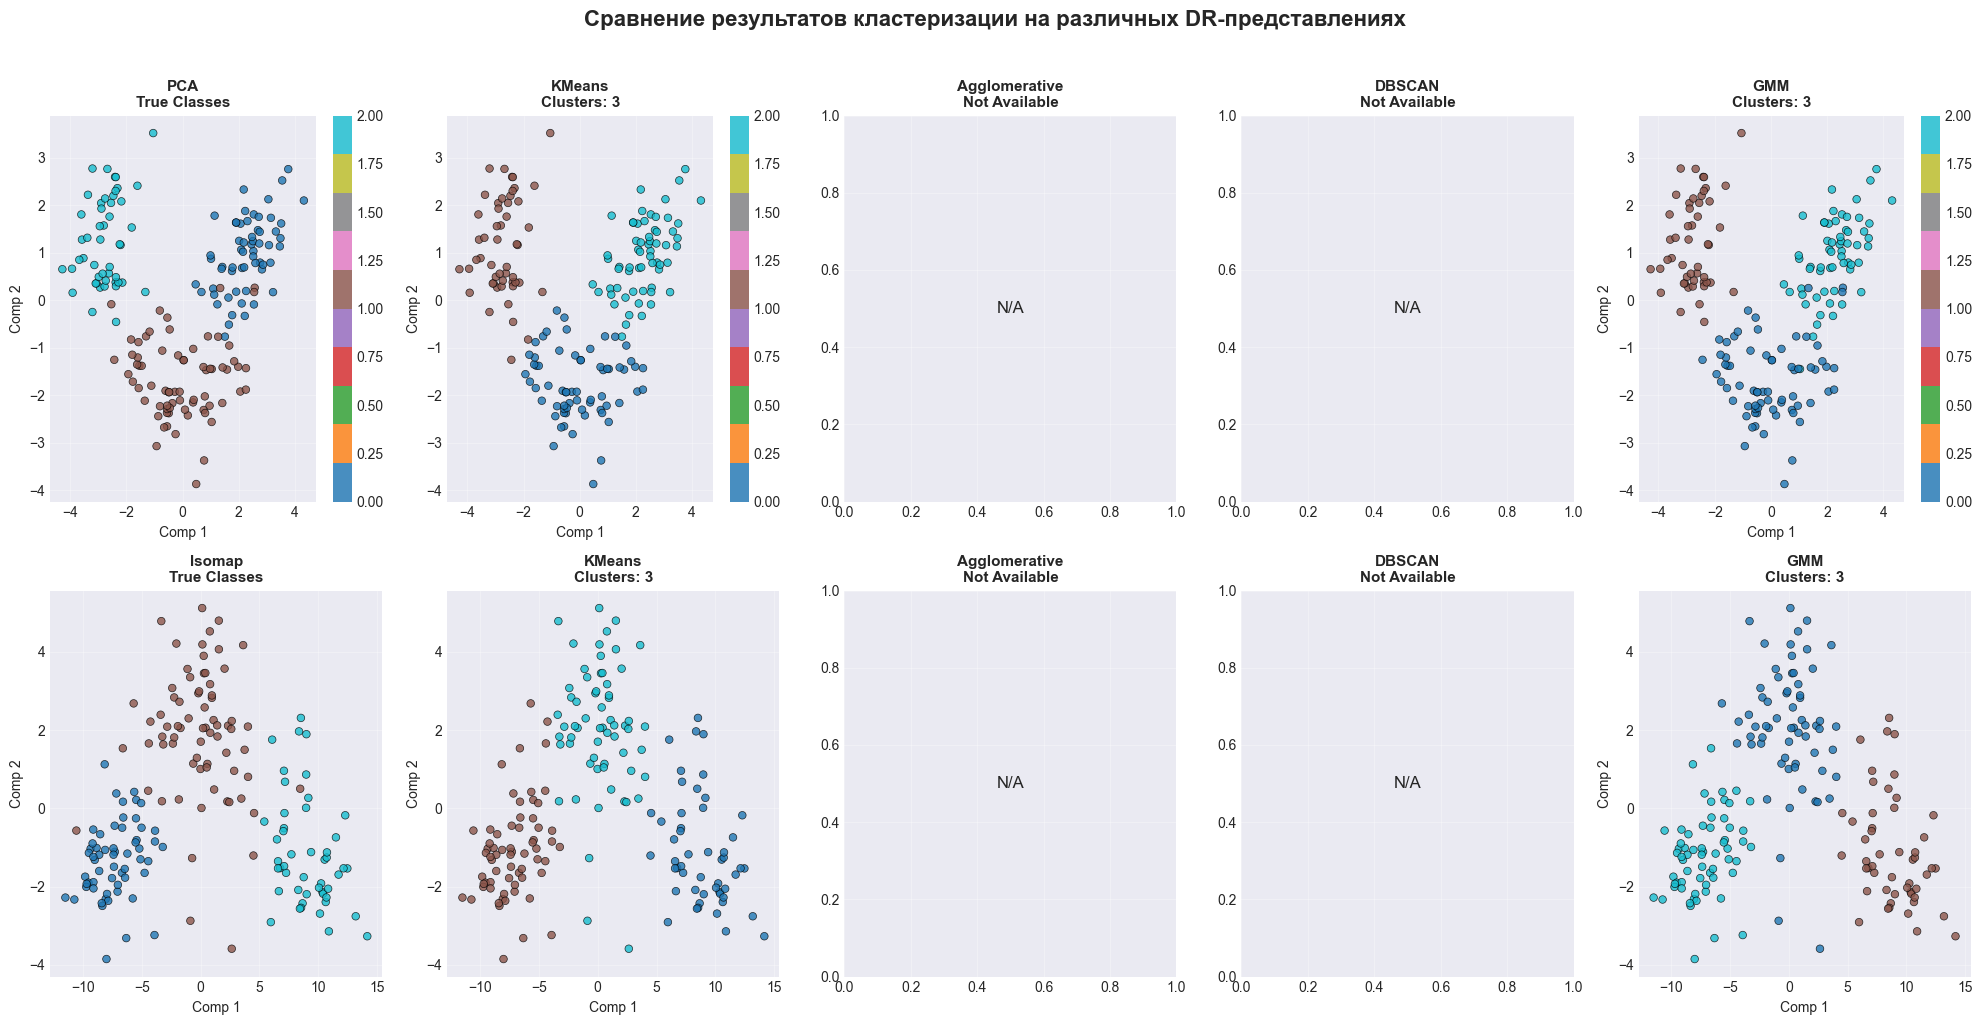



СВОДНЫЙ АНАЛИЗ ПО ВСЕМ НАБОРАМ ДАННЫХ

Набор данных: iris
  Лучшая комбинация (по ARI): t-SNE + Agglomerative = 0.7048
  Лучшая комбинация (по Silhouette): t-SNE + DBSCAN = 0.8789

Набор данных: wine
  Лучшая комбинация (по ARI): PCA + GMM = 0.9651
  Лучшая комбинация (по Silhouette): UMAP + DBSCAN = 0.7498


In [7]:
def experiment_with_multiple_datasets(dataset_names=['iris', 'wine', 'digits']):
    """Эксперименты с различными наборами данных"""
    
    all_results = {}
    
    for dataset_name in dataset_names:
        print(f"\n{'#'*80}")
        print(f"ЭКСПЕРИМЕНТ С НАБОРОМ ДАННЫХ: {dataset_name.upper()}")
        print(f"{'#'*80}")
        
        # Загрузка данных
        X, y_true, data, info = load_dataset(dataset_name)
        
        # Применение DR-методов
        dr_comp = DRComparer(random_state=42)
        dr_res = dr_comp.apply_all_methods(X, n_components_2d=2)
        
        # Выбор оптимального числа кластеров
        if dataset_name == 'iris':
            n_clusters = 3
        elif dataset_name == 'wine':
            n_clusters = 3
        else:  # digits
            n_clusters = 10
        
        # Сравнение алгоритмов кластеризации
        dr_for_clustering = {k: v for k, v in dr_res.items() if k != 'PCA_2D'}
        evaluator, _ = compare_clustering_on_dr(dr_for_clustering, y_true, n_clusters=n_clusters)
        
        # Сохранение результатов
        summary_df = evaluator.get_summary_dataframe()
        summary_df['Dataset'] = dataset_name
        all_results[dataset_name] = summary_df
        
        # Визуализация для этого набора данных
        dr_methods_for_viz = ['PCA', 'Isomap', 't-SNE', 'UMAP']
        dr_results_2d = {
            'PCA': dr_res['PCA_2D'],
            'Isomap': dr_res['Isomap'],
            't-SNE': dr_res['t-SNE'],
            'UMAP': dr_res['UMAP']
        }
        
        # Выбор 2 лучших алгоритмов для визуализации
        best_algorithms = []
        if 'ARI' in summary_df.columns:
            best_ari = summary_df.nlargest(2, 'ARI')['Algorithm'].tolist()
            best_algorithms.extend(best_ari)
        
        if best_algorithms:
            # Оставляем только уникальные алгоритмы
            best_algorithms = list(set(best_algorithms))[:2]
            
            # Создаем кастомный evaluator с только лучшими алгоритмами
            custom_evaluator = ClusteringEvaluator()
            for dr_method in dr_methods_for_viz:
                for algo_name in best_algorithms:
                    key = f"{dr_method}_{algo_name}"
                    if key in evaluator.results:
                        custom_evaluator.results[key] = evaluator.results[key]
            
            # Визуализация
            visualize_clustering_results_2d(dr_results_2d, y_true, 
                                          custom_evaluator, 
                                          dr_methods_for_viz[:2])  # Только 2 метода для наглядности
    
    # Объединение всех результатов
    combined_results = pd.concat(all_results.values(), ignore_index=True)
    
    return combined_results

# Запуск экспериментов с несколькими наборами данных
print("\n\nЭКСПЕРИМЕНТЫ С РАЗЛИЧНЫМИ НАБОРАМИ ДАННЫХ")
combined_results = experiment_with_multiple_datasets(['iris', 'wine'])

# Анализ результатов по всем наборам данных
print("\n\nСВОДНЫЙ АНАЛИЗ ПО ВСЕМ НАБОРАМ ДАННЫХ")
print("="*80)

# Группировка по наборам данных и DR-методам
if 'Dataset' in combined_results.columns:
    for dataset in combined_results['Dataset'].unique():
        print(f"\nНабор данных: {dataset}")
        dataset_df = combined_results[combined_results['Dataset'] == dataset]
        
        # Лучшая комбинация по ARI (если есть)
        if 'ARI' in dataset_df.columns:
            best_ari = dataset_df.loc[dataset_df['ARI'].idxmax()]
            print(f"  Лучшая комбинация (по ARI): {best_ari['DR_Method']} + {best_ari['Algorithm']} = {best_ari['ARI']:.4f}")
        
        # Лучшая комбинация по Silhouette
        if 'Silhouette' in dataset_df.columns:
            best_sil = dataset_df.loc[dataset_df['Silhouette'].idxmax()]
            print(f"  Лучшая комбинация (по Silhouette): {best_sil['DR_Method']} + {best_sil['Algorithm']} = {best_sil['Silhouette']:.4f}")

- Iris: лучший t-SNE/UMAP + Ward (0.70). DBSCAN на t-SNE: 2 кластера, силуэт 0.88 при ARI 0.57.
- Wine: лучший PCA + GMM (0.965) - данные почти линейные; нелинейные методы дают 0.76–0.79.

# Задание для самостоятельной работы
+  Исследование гиперпараметров DR-методов:

   + Изучите влияние параметров каждого DR-метода (n_neighbors для Isomap, perplexity для t-SNE и т.д.)

   + Проведите поиск оптимальных параметров для каждого набора данных

+ Дополнительные алгоритмы кластеризации:

  + Реализуйте и протестируйте OPTICS, Spectral Clustering, BIRCH

  + Сравните их производительность на разных DR-представлениях

+ Анализ устойчивости:

  + Проведите анализ устойчивости результатов к случайным начальным условиям

  + Используйте бутстрап для оценки дисперсии метрик

+ Разработка комплексной оценки:

  + Создайте взвешенную метрику, объединяющую несколько внутренних и внешних метрик

  + Проведите ранжирование комбинаций DR+алгоритм по этой метрике

+ Вопросы для обсуждения:
  + Как выбор метода уменьшения размерности влияет на качество кластеризации?

  + Какие DR-методы лучше сохраняют локальную структуру, а какие - глобальную?

  + Почему t-SNE может давать плохие результаты для кластеризации, несмотря на хорошую визуализацию?

  + Как интерпретировать противоречия между внутренними и внешними метриками?

  + В каких случаях стоит использовать линейные методы (PCA), а в каких - нелинейные (UMAP, t-SNE)?

  + Как время выполнения DR-методов влияет на выбор метода в production-системах?

  + Какие метрики наиболее устойчивы к изменению числа кластеров?

---
# Самостоятельная работа

In [8]:
from sklearn.cluster import OPTICS, SpectralClustering, Birch
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr

def knee_eps(X, k=10):
    """eps для DBSCAN по «колену» графика расстояний до k-го соседа (точка, наиболее удалённая от хорды)."""
    d = np.sort(NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)[0][:, -1])
    x = np.arange(len(d))
    p1, p2 = np.array([0, d[0]]), np.array([len(d) - 1, d[-1]])
    line = (p2 - p1) / np.linalg.norm(p2 - p1)
    vec = np.stack([x, d], axis=1) - p1
    return float(d[np.argmax(np.abs(vec[:, 0] * line[1] - vec[:, 1] * line[0]))])

datasets_all = {}
for name in ['iris', 'wine', 'digits']:
    X_ds, y_ds, _, _ = load_dataset(name)
    datasets_all[name] = (X_ds, y_ds)
    print()

Набор данных: Iris (150 samples, 4 features, 3 classes)
Размерность: (150, 4)
Количество классов: 3

Набор данных: Wine (178 samples, 13 features, 3 classes)
Размерность: (178, 13)
Количество классов: 3

Набор данных: Digits (1797 samples, 64 features, 10 classes)
Размерность: (1797, 64)
Количество классов: 10



## 1. Гиперпараметры DR-методов
KMeans с k = числу классов на вложении; смотрю ARI и силуэт.

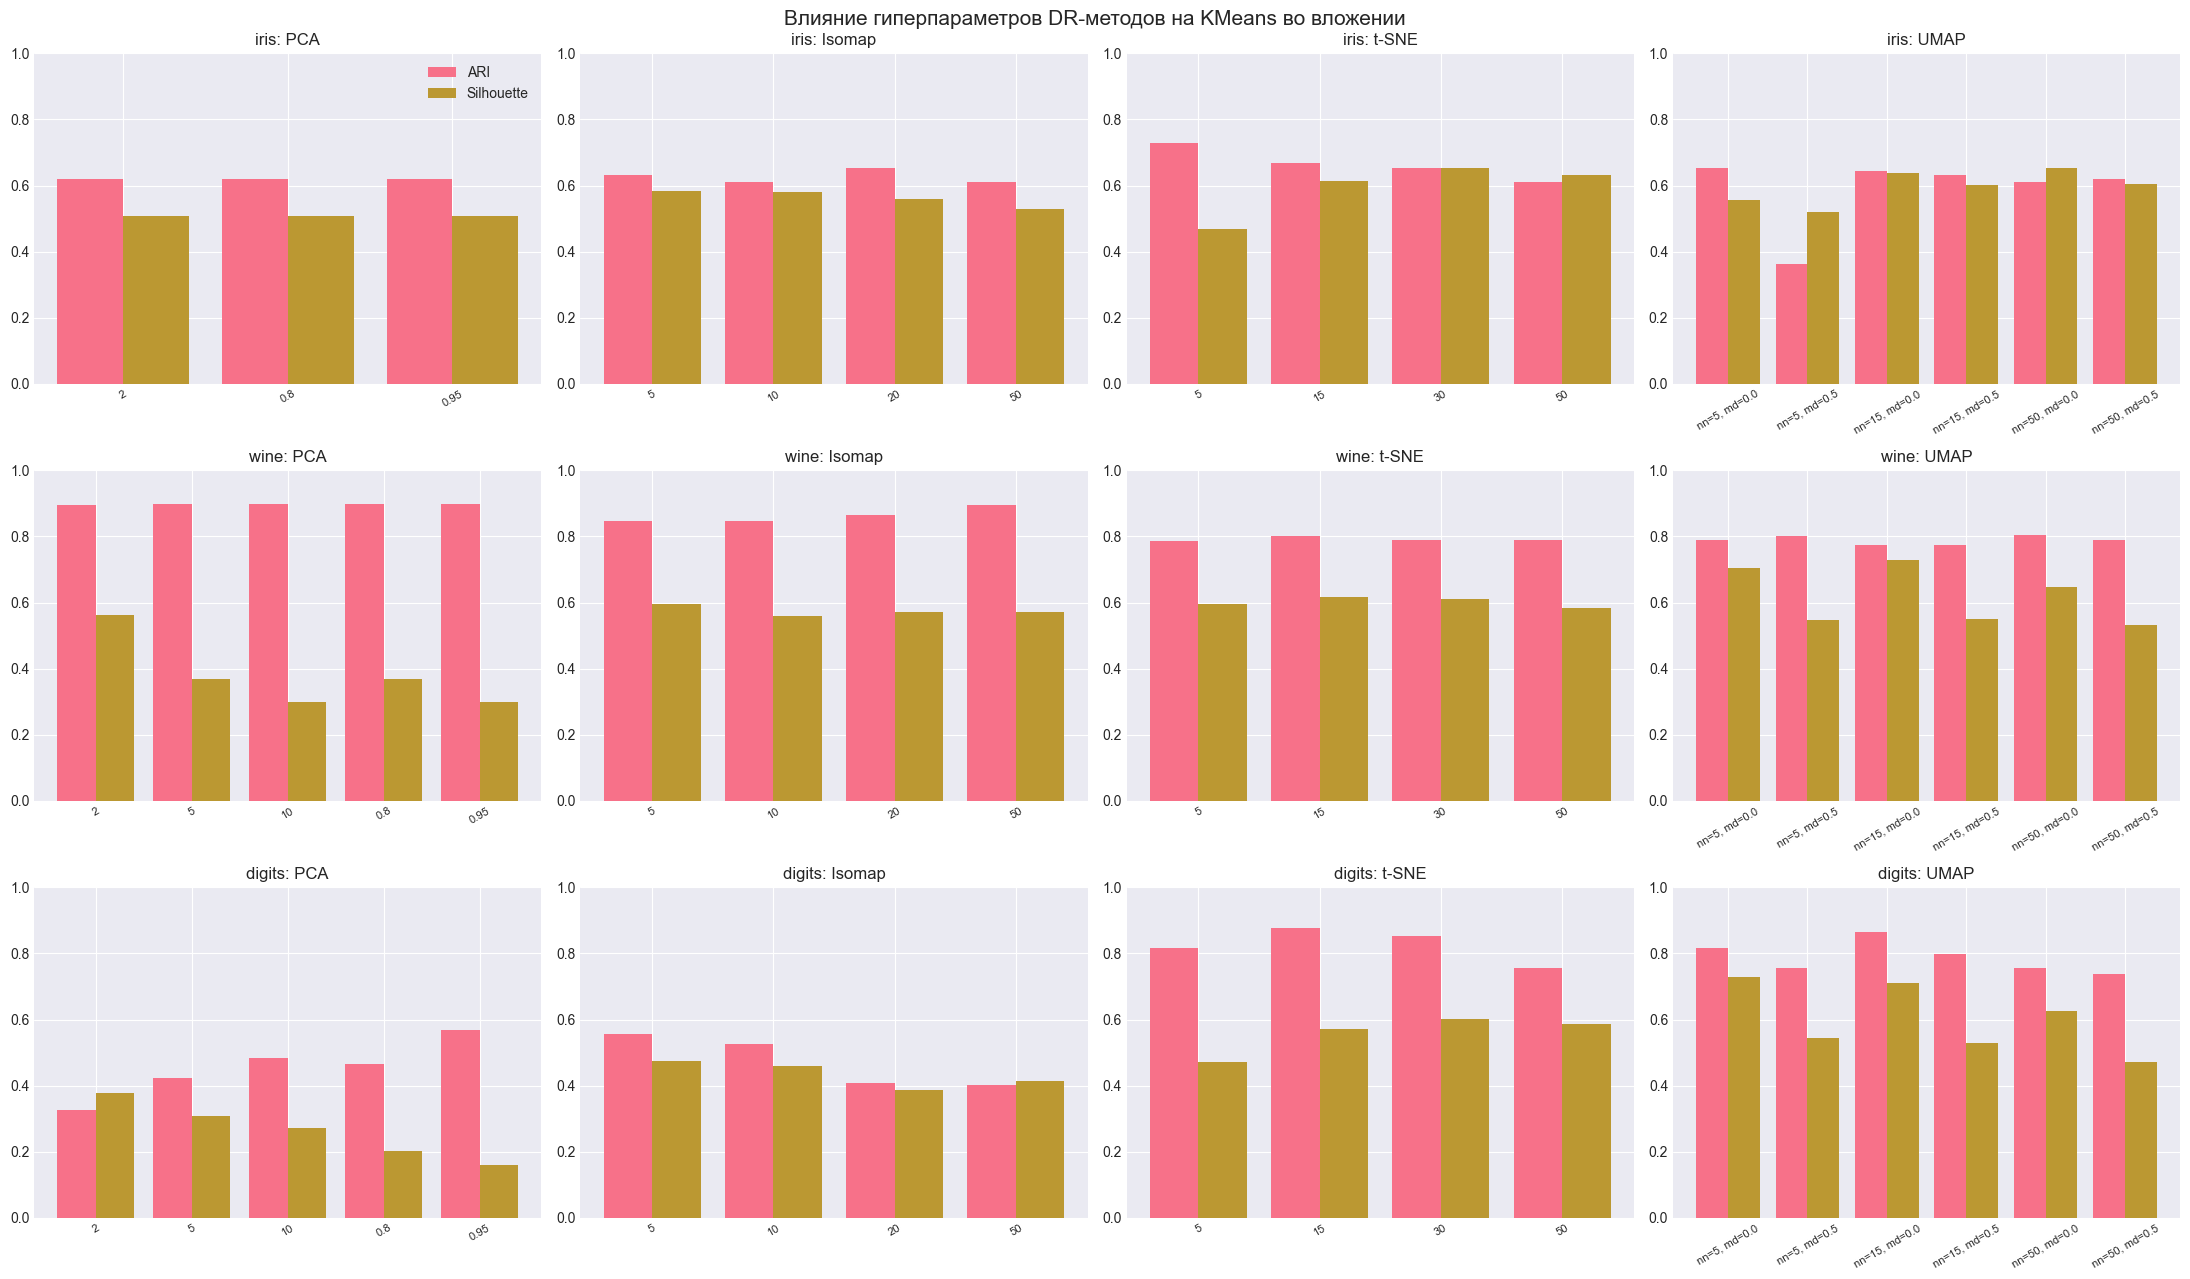

Лучшие параметры (по ARI) для каждого датасета и метода:
Dataset     DR      Параметр  Размерность   ARI  Silhouette  Время, с
 digits Isomap             5            2 0.558       0.474     0.771
 digits    PCA          0.95           40 0.569       0.159     0.001
 digits   UMAP nn=15, md=0.0            2 0.864       0.711     3.562
 digits  t-SNE            15            2 0.878       0.571     3.839
   iris Isomap            20            2 0.652       0.560     0.007
   iris    PCA             2            2 0.620       0.509     0.000
   iris   UMAP  nn=5, md=0.0            2 0.652       0.557     0.091
   iris  t-SNE             5            2 0.729       0.470     0.504
   wine Isomap            50            2 0.896       0.572     0.007
   wine    PCA             5            5 0.897       0.369     0.000
   wine   UMAP nn=50, md=0.0            2 0.804       0.648     0.314
   wine  t-SNE            15            2 0.802       0.618     0.497


In [9]:
def make_reducer(method, param):
    if method == 'PCA':
        return PCA(n_components=param, random_state=42)
    if method == 'Isomap':
        return Isomap(n_components=2, n_neighbors=param)
    if method == 't-SNE':
        return TSNE(n_components=2, perplexity=param, learning_rate=200, random_state=42, n_jobs=-1)
    if method == 'UMAP':
        nn, md_ = param
        return umap.UMAP(n_components=2, n_neighbors=nn, min_dist=md_, random_state=42)

grids = {
    'PCA': [2, 5, 10, 0.8, 0.95],
    'Isomap': [5, 10, 20, 50],
    't-SNE': [5, 15, 30, 50],
    'UMAP': [(nn, md_) for nn in [5, 15, 50] for md_ in [0.0, 0.5]],
}

hp_rows = []
for ds_name, (X_ds, y_ds) in datasets_all.items():
    k = len(np.unique(y_ds))
    for method, values in grids.items():
        for v in values:
            if method == 'PCA' and isinstance(v, int) and v >= X_ds.shape[1]:
                continue  # для Iris нельзя взять больше компонент, чем признаков
            t0 = time.time()
            E = make_reducer(method, v).fit_transform(X_ds)
            dt = time.time() - t0
            lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(E)
            hp_rows.append({'Dataset': ds_name, 'DR': method,
                            'Параметр': str(v) if method != 'UMAP' else f'nn={v[0]}, md={v[1]}',
                            'Размерность': E.shape[1], 'ARI': adjusted_rand_score(y_ds, lab),
                            'Silhouette': silhouette_score(E, lab), 'Время, с': dt})
hp_df = pd.DataFrame(hp_rows)

fig, axes = plt.subplots(3, 4, figsize=(22, 13))
for i, ds_name in enumerate(datasets_all):
    for j, method in enumerate(grids):
        sub = hp_df[(hp_df.Dataset == ds_name) & (hp_df.DR == method)]
        ax = axes[i, j]
        xs = np.arange(len(sub))
        ax.bar(xs - 0.2, sub['ARI'], width=0.4, label='ARI')
        ax.bar(xs + 0.2, sub['Silhouette'], width=0.4, label='Silhouette')
        ax.set_xticks(xs); ax.set_xticklabels(sub['Параметр'], rotation=30, fontsize=8)
        ax.set_ylim(0, 1); ax.set_title(f'{ds_name}: {method}')
        if i == 0 and j == 0:
            ax.legend()
plt.suptitle('Влияние гиперпараметров DR-методов на KMeans во вложении', fontsize=15)
plt.tight_layout(); plt.show()

best_hp = hp_df.loc[hp_df.groupby(['Dataset', 'DR'])['ARI'].idxmax()]
print("Лучшие параметры (по ARI) для каждого датасета и метода:")
print(best_hp[['Dataset', 'DR', 'Параметр', 'Размерность', 'ARI', 'Silhouette', 'Время, с']].round(3).to_string(index=False))

- PCA на digits: больше компонент → ARI растёт (0.33 → 0.57), силуэт падает.
- t-SNE лучше с perplexity 15 (0.88).
- UMAP: min_dist = 0 почти всегда лучше.
- Isomap: на digits лучше k = 5, на Wine k = 50 - оптимум зависит от данных.
- Подбор даёт +0.02…0.10 ARI.

## 2. OPTICS, Spectral, BIRCH (+ DBSCAN с eps по «колену»)

In [10]:
extra_algorithms = [
    ('DBSCAN_auto', lambda Z: DBSCAN(eps=knee_eps(Z, 10), min_samples=10).fit_predict(Z)),
    ('OPTICS', lambda Z: OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.02).fit_predict(Z)),
    ('Spectral', lambda Z: SpectralClustering(n_clusters=10, affinity='nearest_neighbors', n_neighbors=15,
                                              random_state=42).fit_predict(Z)),
    ('BIRCH', lambda Z: Birch(n_clusters=10).fit_predict(Z)),
]

extra_evaluator = ClusteringEvaluator()
for dr_name, X_dr in dr_for_clustering.items():
    for algo_name, algo in extra_algorithms:
        t0 = time.time()
        labels = algo(X_dr)
        dt = time.time() - t0
        m = extra_evaluator.compute_all_metrics(X_dr, labels, y_true, algo_name, dr_name)
        noise = (labels == -1).mean()
        ari = m['external_metrics']['ari'] if m['external_metrics'] else float('nan')
        print(f"{dr_name:>7} | {algo_name:<12} кластеров={m['n_clusters']:>3}, шум={noise:5.1%}, "
              f"ARI={ari:.3f}, {dt:.1f} c")

extra_df = extra_evaluator.get_summary_dataframe()
full_df = pd.concat([summary_df, extra_df], ignore_index=True)
print("\nARI всех алгоритмов на всех DR-представлениях (digits):")
print(full_df.pivot(index='Algorithm', columns='DR_Method', values='ARI').round(3))

    PCA | DBSCAN_auto  кластеров=  2, шум= 2.4%, ARI=0.000, 0.0 c


    PCA | OPTICS       кластеров=  2, шум=97.8%, ARI=0.002, 1.0 c
    PCA | Spectral     кластеров= 10, шум= 0.0%, ARI=0.665, 0.1 c


    PCA | BIRCH        кластеров= 10, шум= 0.0%, ARI=0.604, 0.1 c
 Isomap | DBSCAN_auto  кластеров=  3, шум= 1.6%, ARI=0.001, 0.0 c


 Isomap | OPTICS       кластеров=  9, шум=71.4%, ARI=0.055, 0.5 c
 Isomap | Spectral     кластеров= 10, шум= 0.0%, ARI=0.518, 0.1 c


 Isomap | BIRCH        кластеров= 10, шум= 0.0%, ARI=0.514, 0.0 c
  t-SNE | DBSCAN_auto  кластеров= 16, шум= 3.3%, ARI=0.843, 0.0 c


  t-SNE | OPTICS       кластеров= 15, шум=29.0%, ARI=0.441, 0.5 c
  t-SNE | Spectral     кластеров= 10, шум= 0.0%, ARI=0.726, 0.1 c
  t-SNE | BIRCH        кластеров= 10, шум= 0.0%, ARI=0.773, 0.0 c


   UMAP | DBSCAN_auto  кластеров= 23, шум= 1.9%, ARI=0.761, 0.0 c


   UMAP | OPTICS       кластеров= 20, шум=33.2%, ARI=0.309, 0.6 c
   UMAP | Spectral     кластеров= 10, шум= 0.0%, ARI=0.509, 0.1 c
   UMAP | BIRCH        кластеров= 10, шум= 0.0%, ARI=0.735, 0.0 c

ARI всех алгоритмов на всех DR-представлениях (digits):
DR_Method      Isomap    PCA   UMAP  t-SNE
Algorithm                                 
Agglomerative   0.491  0.604  0.846  0.774
BIRCH           0.514  0.604  0.735  0.773
DBSCAN          0.001  0.051  0.047  0.805
DBSCAN_auto     0.001  0.000  0.761  0.843
GMM             0.536  0.540  0.800  0.779
KMeans          0.558  0.569  0.824  0.853
OPTICS          0.055  0.002  0.309  0.441
Spectral        0.518  0.665  0.509  0.726


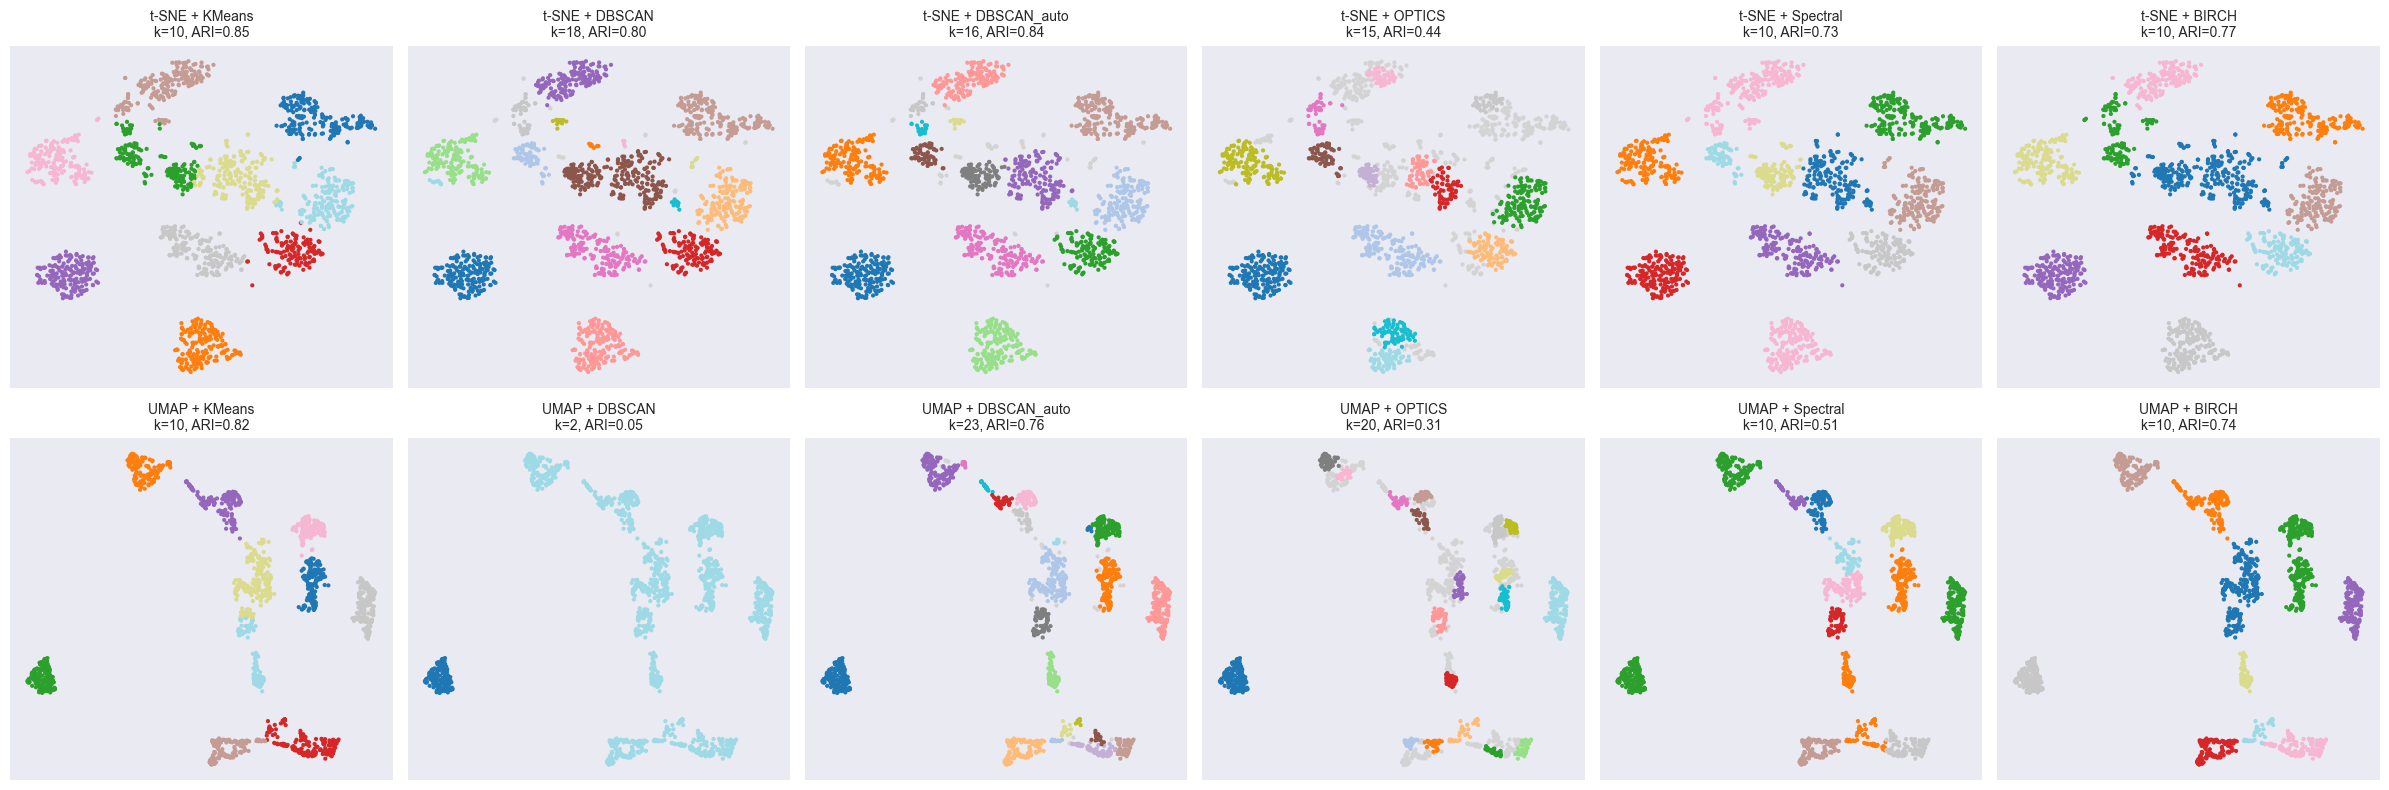

In [11]:
algos_show = ['KMeans', 'DBSCAN', 'DBSCAN_auto', 'OPTICS', 'Spectral', 'BIRCH']
all_results = {**evaluator.results, **extra_evaluator.results}
fig, axes = plt.subplots(2, len(algos_show), figsize=(4 * len(algos_show), 8))
for i, dr_name in enumerate(['t-SNE', 'UMAP']):
    E = dr_results[dr_name]
    for j, algo in enumerate(algos_show):
        key = f'{dr_name}_{algo}'
        ax = axes[i, j]
        if key in all_results:
            lab = all_results[key]['labels']
            ari = all_results[key]['external_metrics']['ari']
            m = lab != -1
            ax.scatter(E[~m, 0], E[~m, 1], c='lightgrey', s=4)
            ax.scatter(E[m, 0], E[m, 1], c=lab[m] % 20, cmap='tab20', s=4)
            ax.set_title(f'{dr_name} + {algo}\nk={all_results[key]["n_clusters"]}, ARI={ari:.2f}', fontsize=10)
        else:
            ax.set_title(f'{dr_name} + {algo}\n(< 2 кластеров)', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

- Spectral лучший на PCA (0.67), BIRCH ведёт себя как Ward.
- OPTICS отбрасывает много точек в шум (ARI ≤ 0.44).
- Автоматический eps чинит DBSCAN на UMAP (0.05 → 0.76), но в 40D не помогает.

## 3. Устойчивость
### 3.1. Пять разных seed

                    ARI        Silhouette       
                   mean    std       mean    std
DR     Algorithm                                
Isomap GMM        0.535  0.024      0.441  0.026
       KMeans     0.557  0.000      0.474  0.000
PCA    GMM        0.535  0.066      0.144  0.008
       KMeans     0.507  0.051      0.157  0.004
UMAP   GMM        0.805  0.043      0.658  0.015
       KMeans     0.822  0.017      0.670  0.007
t-SNE  GMM        0.789  0.032      0.577  0.015
       KMeans     0.770  0.002      0.587  0.005


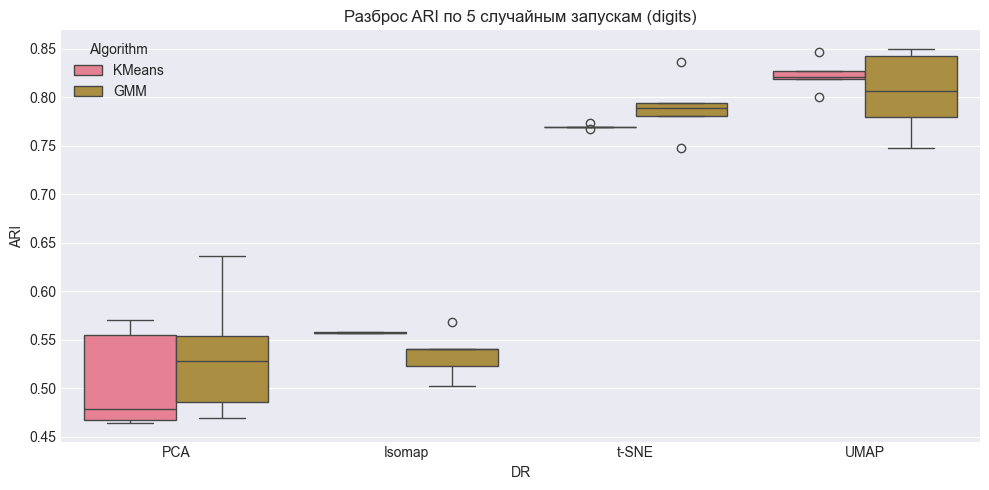

In [12]:
seed_rows = []
for seed in range(5):
    emb = {
        'PCA': dr_results['PCA'],
        'Isomap': dr_results['Isomap'],
        't-SNE': TSNE(n_components=2, perplexity=30, learning_rate=200, random_state=seed, n_jobs=-1).fit_transform(X),
        'UMAP': umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=seed).fit_transform(X),
    }
    for dr_name, E in emb.items():
        for algo_name, model in [('KMeans', KMeans(n_clusters=10, n_init=10, random_state=seed)),
                                 ('GMM', GaussianMixture(n_components=10, random_state=seed))]:
            lab = model.fit_predict(E)
            seed_rows.append({'DR': dr_name, 'Algorithm': algo_name, 'seed': seed,
                              'ARI': adjusted_rand_score(y_true, lab),
                              'Silhouette': silhouette_score(E, lab)})
seed_df = pd.DataFrame(seed_rows)
seed_summary = seed_df.groupby(['DR', 'Algorithm'])[['ARI', 'Silhouette']].agg(['mean', 'std']).round(3)
print(seed_summary)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=seed_df, x='DR', y='ARI', hue='Algorithm', ax=ax)
ax.set_title('Разброс ARI по 5 случайным запускам (digits)')
plt.tight_layout(); plt.show()

### 3.2. Бутстрап, B = 50

Бутстрап (KMeans, B=50): среднее ± СКО [95% ДИ]
                                  ARI                     Silhouette                 Davies_Bouldin                      V_Measure
DR                                                                                                                                
Isomap  0.556 ± 0.014  [0.531; 0.584]  0.475 ± 0.010  [0.449; 0.491]  0.672 ± 0.023  [0.633; 0.711]  0.702 ± 0.011  [0.684; 0.721]
PCA     0.491 ± 0.053  [0.400; 0.584]  0.158 ± 0.010  [0.139; 0.172]  1.686 ± 0.073  [1.542; 1.804]  0.641 ± 0.040  [0.565; 0.709]
UMAP    0.835 ± 0.023  [0.791; 0.868]  0.669 ± 0.005  [0.657; 0.677]  0.463 ± 0.014  [0.445; 0.506]  0.876 ± 0.012  [0.853; 0.894]
t-SNE   0.829 ± 0.034  [0.771; 0.878]  0.605 ± 0.006  [0.594; 0.615]  0.548 ± 0.009  [0.532; 0.561]  0.869 ± 0.017  [0.843; 0.894]


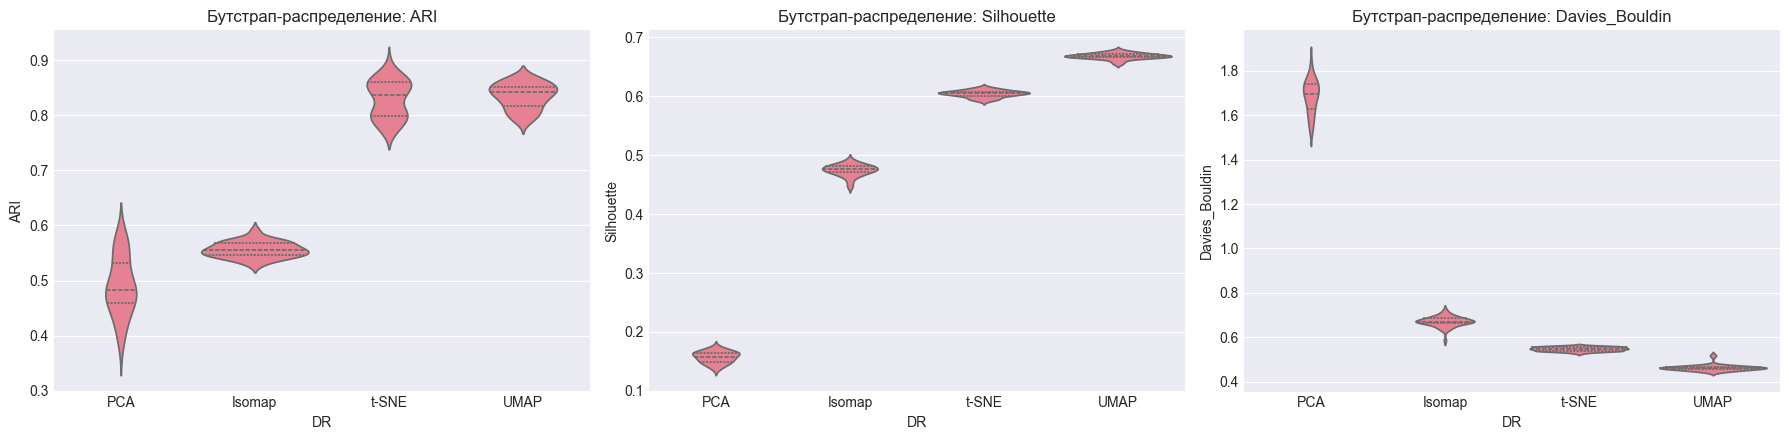

In [13]:
B = 50
rng = np.random.RandomState(0)
boot_rows = []
for dr_name, X_dr in dr_for_clustering.items():
    for b in range(B):
        idx = rng.choice(len(X_dr), size=len(X_dr), replace=True)
        Xb, yb = X_dr[idx], y_true[idx]
        lab = KMeans(n_clusters=10, n_init=5, random_state=b).fit_predict(Xb)
        boot_rows.append({'DR': dr_name, 'ARI': adjusted_rand_score(yb, lab),
                          'Silhouette': silhouette_score(Xb, lab),
                          'Davies_Bouldin': davies_bouldin_score(Xb, lab),
                          'V_Measure': homogeneity_completeness_v_measure(yb, lab)[2]})
boot_df = pd.DataFrame(boot_rows)

def ci(s):
    return f"{s.mean():.3f} ± {s.std():.3f}  [{s.quantile(0.025):.3f}; {s.quantile(0.975):.3f}]"
print("Бутстрап (KMeans, B=50): среднее ± СКО [95% ДИ]")
print(boot_df.groupby('DR').agg(ci).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ['ARI', 'Silhouette', 'Davies_Bouldin']):
    sns.violinplot(data=boot_df, x='DR', y=metric, ax=ax, inner='quartile')
    ax.set_title(f'Бутстрап-распределение: {metric}')
plt.tight_layout(); plt.show()

- PCA + KMeans нестабилен (0.51 ± 0.05), t-SNE/UMAP + KMeans стабильны. GMM менее стабилен, чем KMeans.
- Бутстрап-интервалы: UMAP [0.79; 0.87], t-SNE [0.77; 0.88] - пересекаются; оба лучше PCA и Isomap.

## 4. Комплексная метрика
Min-max нормировка, DB инвертирую; веса 0.6 на внешние и 0.4 на внутренние. Силуэт дополнительно пересчитываю в общем 64D-пространстве.

Ранжирование комбинаций DR + алгоритм (digits) по сбалансированной метрике:
DR_Method     Algorithm  N_Clusters   ARI   AMI  Silhouette  Silhouette_common  Davies_Bouldin  Q сбаланс.  Q внешн.  Q внутр.
     UMAP Agglomerative          10 0.846 0.879       0.667              0.107           0.467       0.882     0.997     0.709
    t-SNE        KMeans          10 0.853 0.874       0.601              0.101           0.554       0.870     0.997     0.681
     UMAP        KMeans          10 0.824 0.867       0.667              0.104           0.461       0.870     0.978     0.708
     UMAP           GMM          10 0.800 0.858       0.661              0.113           0.475       0.861     0.961     0.711
    t-SNE           GMM          10 0.779 0.847       0.590              0.114           0.551       0.840     0.944     0.686
    t-SNE         BIRCH          10 0.773 0.843       0.589              0.113           0.551       0.837     0.938     0.686
    t-SNE Agglomerative          10

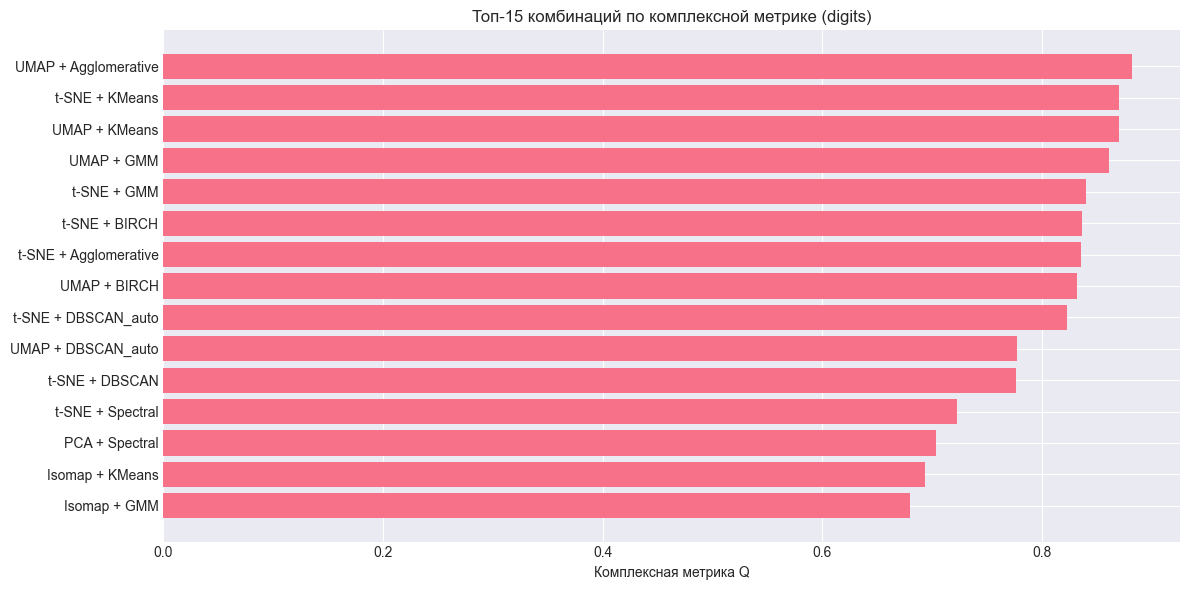

In [14]:
all_results = {**evaluator.results, **extra_evaluator.results}
rank_df = full_df.dropna(subset=['Silhouette']).copy().reset_index(drop=True)
rank_df['Silhouette_common'] = [
    silhouette_score(X, all_results[f'{r.DR_Method}_{r.Algorithm}']['labels'])
    for r in rank_df.itertuples()]

def normalize(s, higher_better=True):
    z = (s - s.min()) / (s.max() - s.min() + 1e-12)
    return z if higher_better else 1 - z

norm = pd.DataFrame({
    'ARI': normalize(rank_df['ARI']), 'AMI': normalize(rank_df['AMI']),
    'V_Measure': normalize(rank_df['V_Measure']),
    'Silhouette_common': normalize(rank_df['Silhouette_common']),
    'Silhouette': normalize(rank_df['Silhouette']),
    'Davies_Bouldin': normalize(rank_df['Davies_Bouldin'], higher_better=False),
})
weight_sets = {
    'Q сбаланс.': {'ARI': .25, 'AMI': .2, 'V_Measure': .15,
                   'Silhouette_common': .2, 'Silhouette': .1, 'Davies_Bouldin': .1},
    'Q внешн.': {'ARI': .4, 'AMI': .35, 'V_Measure': .25},
    'Q внутр.': {'Silhouette_common': .5, 'Silhouette': .25, 'Davies_Bouldin': .25},
}
for wname, w in weight_sets.items():
    rank_df[wname] = sum(norm[m] * wt for m, wt in w.items())

main = 'Q сбаланс.'
top = rank_df.sort_values(main, ascending=False)
print("Ранжирование комбинаций DR + алгоритм (digits) по сбалансированной метрике:")
print(top[['DR_Method', 'Algorithm', 'N_Clusters', 'ARI', 'AMI', 'Silhouette', 'Silhouette_common',
           'Davies_Bouldin'] + list(weight_sets)].round(3).to_string(index=False))

print("\nСилуэт в общем 64-мерном пространстве (min / max по алгоритмам):")
print(rank_df.groupby('DR_Method')['Silhouette_common'].agg(['min', 'max']).round(3))

print("\nСогласованность ранжирований (корреляция Спирмена):")
names_w = list(weight_sets)
for a in range(len(names_w)):
    for b in range(a + 1, len(names_w)):
        rho = spearmanr(rank_df[names_w[a]], rank_df[names_w[b]]).correlation
        print(f"  {names_w[a]}  vs  {names_w[b]}: rho = {rho:.3f}")

fig, ax = plt.subplots(figsize=(12, 6))
lbl = top['DR_Method'] + ' + ' + top['Algorithm']
ax.barh(lbl.head(15)[::-1], top[main].head(15)[::-1])
ax.set_xlabel('Комплексная метрика Q'); ax.set_title('Топ-15 комбинаций по комплексной метрике (digits)')
plt.tight_layout(); plt.show()

- Топ: UMAP + Ward, t-SNE + KMeans, UMAP + KMeans.
- В общем пространстве силуэт нормальных разбиений ≈ 0.1, а максимум (0.53) - у вырожденного разбиения с ARI 0.
- Согласованность ранжирований: сбалансированная vs внешняя ρ = 0.94, только внутренняя - 0.48–0.68.

## 5. Вопросы для обсуждения
1. Выбор DR влияет сильнее выбора алгоритма: ARI на digits от 0.56 (PCA) до 0.85 (t-SNE).
2. Локальную структуру держат t-SNE и UMAP, глобальную - PCA, Isomap, TriMAP/PaCMAP.
3. t-SNE искажает размеры кластеров и расстояния между ними, создаёт ложные кластеры, не умеет `transform`.
4. Внутренние метрики - про геометрию в конкретном пространстве, внешние - про согласие с разметкой.
5. PCA - для почти линейных данных, скорости, `transform` и интерпретации; UMAP/t-SNE - для нелинейных многообразий.
6. В production важны `transform` новых точек и масштабируемость: PCA/UMAP - да, t-SNE - только офлайн.
7. AMI устойчивее к числу кластеров; V-measure растёт с k, CH несравним.

## Итог
- Лучшие комбинации на digits: t-SNE + KMeans и UMAP + Ward (ARI ≈ 0.85); на Wine - PCA + GMM.
- Подбор гиперпараметров даёт до +0.1 ARI.
- Внутренние метрики нельзя сравнивать между разными пространствами.